# Length of intrinsic transcription terminators in the TERMITe atlas

**Source data** — `Kosinski_2025_term-seq_sources_terminators_altas/`

* `Supplementary Table 1.xlsx` — the 17 Term-seq datasets (13 species), their studies,
  protocols and TERMITe settings.
* `Supplementary Table 2.xlsx` — the atlas itself: **11,769 intrinsic terminators**,
  one row per terminator, with TransTermHP- and RNAfold-derived hairpin annotations.

Reference: Kosiński *et al.* (2025) *Nucleic Acids Research* **53**, gkaf553 —
"Characterization of bacterial intrinsic transcription terminators identified with TERMITe
— a novel method for comprehensive analysis of Term-seq data."

**Terminator length is defined as `A-tract + hairpin (stem + loop) + U-tract`**, summed, and
computed **separately for each of the two annotation protocols** in the atlas. §2 spells
out exactly which columns go into that sum and what it does and does not vary with.

**What this notebook answers**

1. What is the distribution and range of intrinsic-terminator length, per protocol?
2. How does it differ **by species / dataset**?
3. How does it differ between datasets that **do** and **do not** have termination
   efficiency (TE) measured?

Everything is written with the downstream TE-prediction model in mind: §9 turns the
distributions into a concrete input-window recommendation and §10 collects the takeaways.

## 0. Setup

Only `numpy` / `pandas` / `matplotlib` / `scipy` / `openpyxl` are required (no seaborn),
so the notebook runs in any of the Python environments on this machine.

Colours follow a categorical palette validated for colour-vision-deficiency separation:
**blue = datasets with TE measured**, **orange = datasets without TE**. That pairing is
used consistently in every figure below.

In [1]:
from pathlib import Path
import re, sys, textwrap, warnings

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy import stats
import openpyxl

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 80)

# ---- paths -------------------------------------------------------------
def find_project_root(start):
    for p in [start, *start.parents]:
        if (p / "Kosinski_2025_term-seq_sources_terminators_altas").is_dir():
            return p
    raise FileNotFoundError("Could not locate the Kosinski data folder.")

PROJECT  = find_project_root(Path.cwd().resolve())
DATA_DIR = PROJECT / "Kosinski_2025_term-seq_sources_terminators_altas"
ST1      = DATA_DIR / "Supplementary Table 1.xlsx"
ST2      = DATA_DIR / "Supplementary Table 2.xlsx"

OUT = PROJECT / "outputs" / "terminator_length"
FIG, TAB = OUT / "figures", OUT / "tables"
for d in (FIG, TAB):
    d.mkdir(parents=True, exist_ok=True)

print("project :", PROJECT)
print("figures :", FIG)
print("tables  :", TAB)
print("python  :", sys.version.split()[0], "| pandas", pd.__version__,
      "| matplotlib", mpl.__version__, "| scipy", __import__("scipy").__version__)

project : C:\Users\Deart\OneDrive\Desktop\Programming\TE_model
figures : C:\Users\Deart\OneDrive\Desktop\Programming\TE_model\outputs\terminator_length\figures
tables  : C:\Users\Deart\OneDrive\Desktop\Programming\TE_model\outputs\terminator_length\tables
python  : 3.13.9 | pandas 3.0.2 | matplotlib 3.10.9 | scipy 1.17.1


In [2]:
# ---- palette & chart style --------------------------------------------
SURFACE, INK, INK2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, AXIS = "#e1e0d9", "#c3c2b7"

SER = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "yellow": "#eda100",
       "magenta": "#e87ba4", "green": "#008300", "violet": "#4a3aa7", "red": "#e34948"}

TE_MEASURED, TE_NONE = "TE measured", "no TE"
TE_COLOR = {TE_MEASURED: SER["blue"], TE_NONE: SER["orange"]}

mpl.rcParams.update({
    "figure.facecolor": SURFACE, "figure.dpi": 120, "savefig.dpi": 200,
    "savefig.facecolor": SURFACE, "savefig.bbox": "tight",
    "axes.facecolor": SURFACE, "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "axes.labelsize": 9.5, "axes.grid": False,
    "grid.color": GRID, "grid.linewidth": 0.7, "grid.linestyle": "-",
    "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "text.color": INK, "legend.frameon": False, "legend.fontsize": 8.5,
    "font.family": "sans-serif",
    "font.sans-serif": ["Segoe UI", "DejaVu Sans", "Arial", "sans-serif"],
    "font.size": 9.5,
})

def style_axes(ax, grid=None, hide=("top", "right")):
    # Hairline, recessive chrome. grid in {None, 'x', 'y', 'both'}.
    for s in hide:
        ax.spines[s].set_visible(False)
    for s in ax.spines.values():
        s.set_color(AXIS)
        s.set_linewidth(0.8)
    ax.tick_params(length=3, width=0.8, color=AXIS)
    if grid:
        ax.grid(True, axis="both" if grid == "both" else grid,
                color=GRID, lw=0.7, ls="-", zorder=0)
        ax.set_axisbelow(True)
    return ax

def fig_note(fig, text, y=0.0):
    fig.text(0.0, y, textwrap.fill(text, 145), ha="left", va="top",
             fontsize=8, color=MUTED)

def save(fig, name):
    p = FIG / (name + ".png")
    fig.savefig(p)
    print("saved:", p.relative_to(PROJECT))

## 1. Load the two supplementary tables

`Supplementary Table 2` is read with **openpyxl rather than `pd.read_excel`** on purpose:
three `transtermhp hairpin` cells begin with `=`, so Excel stores them as formulas and
pandas returns `NaN` for them. Reading raw cell values keeps all 11,769 rows intact.

In [3]:
def load_atlas(path=ST2):
    wb = openpyxl.load_workbook(path, read_only=True, data_only=False)
    ws = wb["Atlas of intrinsic terminators"]
    it = ws.iter_rows(values_only=True)
    next(it)                                     # row 1 = table title
    header = [str(h).strip() for h in next(it)]  # row 2 = the real header
    rows = [list(r) for r in it]
    wb.close()
    out = pd.DataFrame(rows, columns=header)
    return out[out["Species"].notna()].reset_index(drop=True)


def load_dataset_table(path=ST1):
    # keep_default_na=False: the --min-upstream column literally reads "N/A" for the
    # datasets without matched RNA-seq, and pandas would otherwise turn that into NaN.
    d = pd.read_excel(path, sheet_name="Term-seq Datasets", header=1,
                      keep_default_na=False, na_values=[""])
    d = d.iloc[:, :9]
    d = d[d.iloc[:, 0].notna()].copy()
    d.columns = ["bioproject", "organism", "dataset", "reference", "sra",
                 "protocol", "sample_description", "genome", "min_upstream"]
    for c in ["organism", "dataset", "reference", "protocol", "genome"]:
        d[c] = d[c].astype(str).str.strip()
    d["min_upstream"] = d["min_upstream"].astype(str).str.strip()
    d["n_runs"] = d["sra"].astype(str).str.count("SRR|ERR")
    # TERMITe computes TE only where matched RNA-seq exists, i.e. --min-upstream is set
    d["te_expected"] = np.where(d["min_upstream"].str.upper().eq("N/A"), TE_NONE, TE_MEASURED)
    return d.reset_index(drop=True)


atlas = load_atlas()
dsets = load_dataset_table()
print("atlas   :", atlas.shape)
print("datasets:", dsets.shape)
atlas.head(3)

atlas   : (11769, 36)
datasets: (17, 11)


,Species,chromosome,start,end,POT,sequence,strand,termite id,termite score,average peak height,termination efficiency,IDR,summit coordinate,overlapping gene,upstream gene,downstream gene,overlapping feature types,transtermhp closest hairpin start,transtermhp closest hairpin end,transtermhp id,transtermhp confidence,transtermhp hairpin score,transtermhp tail score,transtermhp a tract,transtermhp hairpin,transtermhp u tract,transtermhp POT distance to hairpin,rnafold a tract,rnafold hairpin,rnafold u tract,rnafold hairpin structure,rnafold POT distance to hairpin,rnafold energy,rnafold,transtermhp,None
0,Streptomyces avermitilis,NC_003155.5,44060,44067,44062,tggtgtgggacggtccggcgcatccgcgggacccggaatggacacg...,-,WT_3prime_signal_reverse_19,1000,45145,.,0.0,44062,.,gene-SAVERM_RS00615 - 40bp,gene-SAVERM_RS00605 - 2093bp,.,44067,44107,TERM_15,82,-18.4,-3.3,gacacgcttcgcata,gcactgtggccggaatacc acag ggtgctccggccacag-gc,ttggTcattcaaggg,4,cacgcttcgcatagc,actgtggccggaataccacagggtgctccggccacagg,cttggtcattcaagg,.(((((((((((.((((....)))).))))))))))).,5,-28.600000381469727,+,+,None
1,Streptomyces avermitilis,NC_003155.5,44107,44108,44108,aacgccgacacggtctgcgcgtggaagaaggtcggctgacctgacc...,+,WT_3prime_signal_forward_23,1000,187.3,.,0.0,44108,.,gene-SAVERM_RS00610 - 61bp,gene-SAVERM_RS00635 - 5148bp,region,44069,44104,TERM_16,85,-19.8,-2.6,cttgaatgaccaagc,ctgtggccggagcacc ctgt ggtattccggccacag,tgcTatgcgaagcgt,3,cttgaatgaccaagc,ctgtggccggagcaccctgtggtattccggccacag,tgctatgcgaagcgt,((((((((((((.(((....))).)))))))))))),3,-26.0,+,+,None
2,Streptomyces avermitilis,NC_003155.5,69454,69455,69455,cagaacatcggcaacttctgcacggtggtcggccccgtcgaggact...,+,WT_3prime_signal_forward_39,1000,46.8,.,0.0,69455,.,gene-SAVERM_RS00730 - 52bp,gene-SAVERM_RS00745 - 2734bp,region,69421,69451,TERM_30,87,-20.4,-3.2,aggacgccgtgaaga,gctggtcccgcccc ttt ggcgcgggaccggc,ttgCgttgcgccgcc,3,aggacgccgtgaaga,gctggtcccgcccctttggcgcgggaccggc,ttgcgttgcgccgcc,(((((((((((((....)).))))))))))),3,-25.200000762939453,+,+,None


In [4]:
# ---- join the dataset metadata onto every terminator -------------------
# Supplementary Table 1 spells one label differently from the atlas.
ALIAS = {"Streptomyces tsukubaensis": "Streptomyces tsukubensis"}
dsets["dataset_key"] = dsets["dataset"].str.strip().replace(ALIAS)

missing = set(atlas["Species"].unique()) - set(dsets["dataset_key"])
assert not missing, "unmapped atlas labels: {}".format(missing)

meta_cols = ["dataset_key", "bioproject", "organism", "reference", "protocol",
             "min_upstream", "n_runs", "te_expected"]
df = atlas.merge(dsets[meta_cols], left_on="Species", right_on="dataset_key", how="left")
df = df.rename(columns={"Species": "dataset"}).drop(columns=["dataset_key"])
print("{:,} terminators joined to {} datasets / {} organisms".format(
    len(df), df["dataset"].nunique(), df["organism"].nunique()))
dsets[["bioproject", "dataset", "reference", "protocol", "min_upstream", "n_runs", "te_expected"]]

11,769 terminators joined to 17 datasets / 13 organisms


,bioproject,dataset,reference,protocol,min_upstream,n_runs,te_expected
0,PRJNA792588,Bacillus subtilis (a),Chabbra et al. 2022,Mondal et al. 2016,1.79,12,TE measured
1,PRJNA646522,Bacillus subtilis (b),Mandell et al. 2021,Mondal et al. 2016,12.22,8,TE measured
2,PRJEB12568,Bacillus subtilis (c),Dar et al. 2016,Dar et al. 2016,N/A,25,no TE
3,PRJNA278818,Bacillus subtilis (d),Mondal et al. 2016,Mondal et al. 2016,10.17,12,TE measured
4,PRJEB12568,Enterococcus faecalis,Dar et al. 2016,Dar et al. 2016,N/A,23,no TE
5,PRJNA906280,Escherichia coli (a),this study,Mondal et al. 2016,6.5,3,TE measured
6,PRJEB36932,Escherichia coli (b),Choe et al. 2022,Dar et al. 2016,N/A,3,no TE
7,PRJEB12568,Listeria monocytogenes,Dar et al. 2016,Dar et al. 2016,N/A,24,no TE
8,PRJNA486172,Streptomyces avermitilis,Lee et al. 2020,Dar et al. 2016,N/A,2,no TE
9,PRJNA575515,Streptomyces clavuligerus,Hwang et al. 2021,Dar et al. 2016,N/A,2,no TE


## 2. What "the length of an intrinsic terminator" means here

An intrinsic terminator is not a single annotated interval in this atlas — it is
reconstructed from parts, each stored in its own column:

```
 5' ... A-tract ...  [ ==== stem ==== loop ==== stem ==== ]  ... U-tract ... 3'
                      \_________ hairpin (stem-loop) ______/
                                                            ^ POT = the 3' RNA end
```

TERMITe annotates each 3′ end (POT) with **two independent pipelines** and the atlas
stores both:

| pipeline | columns | window / limits |
|---|---|---|
| **TransTermHP protocol** (default settings) | `transtermhp *` | canonical terminators only: stem ≥ 4, loop 3–13, stem-loop ≤ **59 nt** |
| **RNAfold protocol** (permissive TransTermHP scan −80…+30 nt around the POT, then RNAfold refold) | `rnafold *` | run with `--max-len 40`, so hairpins are capped at **40 nt** |

A terminator enters the atlas if **either** pipeline confirms it (`transtermhp` /
`rnafold` = `+`), which is why 8,212 rows carry TransTermHP annotation and 10,720 carry
RNAfold annotation.

### Terminator length = A-tract + hairpin + U-tract, computed per protocol

The **terminator length** used throughout is the whole annotated element, summed:

```
terminator length  =  A-tract  +  hairpin (stem + loop)  +  U-tract
```

and it is built **separately for each protocol**, because each protocol places the hairpin
boundaries — and therefore its own flanking tracts — independently.

| variable | definition | n |
|---|---|---|
| **`tt_terminator_len`** | TransTermHP: `a tract` + `hairpin` + `u tract` | 8,212 |
| **`rf_terminator_len`** | RNAfold: `a tract` + `hairpin` + `u tract` | 10,720 |
| **`terminator_len`** | **primary** — `tt_terminator_len` where TransTermHP confirmed the terminator, else `rf_terminator_len` | 11,769 |

**One thing to know before reading any number below.** In both protocols the atlas' `a tract`
and `u tract` columns are **exactly 15 nt on every single row** — they are fixed reporting
windows around the hairpin, not measured tract lengths. So the sum above is arithmetically
`hairpin + 30` for every terminator: the distribution of terminator length is the hairpin
distribution shifted by a constant, and every between-species and between-protocol
comparison is numerically identical to the hairpin comparison. That is not a reason to
avoid the sum — it is the terminator as each protocol defines and reports it, and it is the
right footprint to quote for an input window — but it does mean the *shape* of every
distribution below comes from the hairpin.

For that reason the notebook also carries a **sequence-measured** variant, where the tracts
are the real homopolymer runs read off the genomic sequence instead of the 15-nt windows:

| variable | definition |
|---|---|
| `tt_a_run`, `rf_a_run` | uninterrupted A run ending immediately 5′ of that protocol's hairpin |
| `tt_u_run`, `rf_u_run` | uninterrupted U(T) run starting immediately 3′ of that protocol's hairpin |
| `tt_terminator_len_seq`, `rf_terminator_len_seq` | `a_run + hairpin + u_run`, per protocol |
| `terminator_len_seq` | coalesced primary of the two |

Supporting components, also kept per protocol and coalesced:

| variable | definition |
|---|---|
| `hairpin_len` | stem-loop length (stem + loop) |
| `stem_nt`, `loop_nt` | nucleotides paired in the stem (both arms) / in the apical loop |
| `peak_width` | width of the merged Term-seq 3′-end peak — a property of the *signal*, not of the terminator |

**Why the coalescing rule is "TransTermHP first, else RNAfold":** the paper reports
Kruskal–Wallis *H* = 3207.36 for hairpin length across the 17 datasets. Of every candidate
definition, only that order reproduces it — verified in §3 below. Its per-dataset medians
also fall inside the ranges quoted in the Results (*Streptomyces* 32–35 nt, *E. faecalis*
33 nt, everything else 20–28 nt). Since terminator length is hairpin + 30, the same rule
carries over unchanged.

In [5]:
# ---- parsers -----------------------------------------------------------
DOT = {".", "", "None", "nan"}

def parse_transtermhp_hairpin(s):
    # TransTermHP writes "<5' arm> <loop> <3' arm>"; '-' marks a bulge gap.
    # A few cells start with '=' (Excel read them as formulas) - strip it.
    # Returns (stem_nt, loop_nt, stemloop_nt).
    if s is None:
        return (np.nan,) * 3
    s = str(s).lstrip("=")
    if s.strip() in DOT:
        return (np.nan,) * 3
    parts = [p for p in s.split(" ") if p]
    if len(parts) != 3:
        return (np.nan,) * 3
    a5, loop, a3 = (p.replace("-", "") for p in parts)
    return len(a5) + len(a3), len(loop), len(a5) + len(loop) + len(a3)


def parse_rnafold_structure(struct):
    # Dot-bracket MFE structure -> (stem_nt, loop_nt, total_len).
    if struct is None:
        return (np.nan,) * 3
    s = str(struct)
    if s.strip() in DOT or "(" not in s:
        return (np.nan,) * 3
    open_i = s.rfind("(")             # innermost pair -> apical loop
    close_i = s.find(")", open_i)
    return 2 * s.count("("), close_i - open_i - 1, len(s)


def leading_run(seq, base):
    # Length of the run of `base` at the 5' end of `seq` (case-insensitive).
    if seq is None or str(seq).strip() in DOT:
        return np.nan
    s = str(seq).lower()
    n = 0
    while n < len(s) and s[n] == base:
        n += 1
    return n


def trailing_run(seq, base):
    if seq is None or str(seq).strip() in DOT:
        return np.nan
    s = str(seq).lower()
    n = 0
    while n < len(s) and s[len(s) - 1 - n] == base:
        n += 1
    return n


def count_base(seq, base, first_n=None):
    if seq is None or str(seq).strip() in DOT:
        return np.nan
    s = str(seq).lower()
    if first_n:
        s = s[:first_n]
    return s.count(base)


def gc_fraction(seq):
    if seq is None or str(seq).strip() in DOT:
        return np.nan
    s = re.sub(r"[^acgtu]", "", str(seq).lower())
    return (s.count("g") + s.count("c")) / len(s) if s else np.nan

In [6]:
# ---- build the feature table ------------------------------------------
tt = df["transtermhp hairpin"].map(parse_transtermhp_hairpin)
df["tt_stem_nt"]     = [x[0] for x in tt]
df["tt_loop_nt"]     = [x[1] for x in tt]
df["tt_hairpin_len"] = [x[2] for x in tt]

rf = df["rnafold hairpin structure"].map(parse_rnafold_structure)
df["rf_stem_nt"]     = [x[0] for x in rf]
df["rf_loop_nt"]     = [x[1] for x in rf]
df["rf_hairpin_len"] = [x[2] for x in rf]

# ---- per-protocol A / U tracts -----------------------------------------
TRACT_COLS = {"tt": ("transtermhp a tract", "transtermhp u tract", "transtermhp hairpin"),
              "rf": ("rnafold a tract", "rnafold u tract", "rnafold hairpin")}

for pre, (acol, ucol, hcol) in TRACT_COLS.items():
    # the reported windows (fixed width - assert it rather than assume it)
    a_w = df[acol].map(lambda s: np.nan if s is None or str(s).strip() in DOT else len(str(s)))
    u_w = df[ucol].map(lambda s: np.nan if s is None or str(s).strip() in DOT else len(str(s)))
    assert set(a_w.dropna().unique()) == {15} and set(u_w.dropna().unique()) == {15}, \
        "{}: a/u tract windows are not uniformly 15 nt".format(pre)
    df[pre + "_a_window"] = a_w
    df[pre + "_u_window"] = u_w
    # the real homopolymer runs abutting this protocol's hairpin
    df[pre + "_a_run"] = df[acol].map(lambda s: trailing_run(s, "a"))
    df[pre + "_u_run"] = df[ucol].map(lambda s: leading_run(s, "t"))
    df[pre + "_u_in_first8"] = df[ucol].map(lambda s: count_base(s, "t", 8))
    df[pre + "_hairpin_gc"] = df[hcol].map(gc_fraction)
    # TERMINATOR LENGTH = A tract + hairpin + U tract, per protocol
    df[pre + "_terminator_len"] = (df[pre + "_a_window"] + df[pre + "_hairpin_len"]
                                   + df[pre + "_u_window"])
    df[pre + "_terminator_len_seq"] = (df[pre + "_a_run"] + df[pre + "_hairpin_len"]
                                       + df[pre + "_u_run"])

# ---- coalesce: TransTermHP where it confirmed the terminator, else RNAfold
use_tt = df["tt_hairpin_len"].notna()
df["length_source"] = np.where(use_tt, "TransTermHP", "RNAfold")
for name in ["hairpin_len", "stem_nt", "loop_nt", "a_run", "u_run", "u_in_first8",
             "hairpin_gc", "terminator_len", "terminator_len_seq"]:
    df[name] = df["tt_" + name].fillna(df["rf_" + name])

df["context_gc"] = df["sequence"].map(gc_fraction)      # 111-nt window centred on the POT

# signal-side quantities
df["peak_width"] = (pd.to_numeric(df["end"], errors="coerce")
                    - pd.to_numeric(df["start"], errors="coerce") + 1)
df["mfe"] = pd.to_numeric(df["rnafold energy"], errors="coerce")
df["pot_to_hairpin"] = pd.to_numeric(
    df["transtermhp POT distance to hairpin"].where(use_tt, df["rnafold POT distance to hairpin"]),
    errors="coerce")

# the sum is exact by construction; check it
assert (df["terminator_len"] - df["hairpin_len"]).dropna().eq(30).all()

LEN_VARS = ["tt_terminator_len", "rf_terminator_len", "terminator_len",
            "tt_terminator_len_seq", "rf_terminator_len_seq", "terminator_len_seq",
            "hairpin_len", "stem_nt", "loop_nt", "a_run", "u_run", "peak_width"]
print(df[LEN_VARS].describe().round(2).to_string())

       tt_terminator_len  rf_terminator_len  terminator_len  tt_terminator_len_seq  rf_terminator_len_seq  terminator_len_seq  hairpin_len   stem_nt   loop_nt     a_run     u_run  peak_width
count            8212.00           10720.00        11769.00                8212.00               10720.00            11769.00     11769.00  11769.00  11769.00  11769.00  11769.00    11769.00
mean               57.92              58.20           58.82                  34.79                  33.39               34.41        28.82     23.12      4.74      1.85      3.75        4.80
std                 7.96               6.86            7.65                   7.11                   5.98                6.85         7.65      7.36      1.71      2.12      2.29        1.82
min                41.00              42.00           41.00                  17.00                  13.00               14.00        11.00      8.00      3.00      0.00      0.00        2.00
25%                52.00              53.00  

In [7]:
# ---- termination efficiency: repair two Excel artefacts ----------------
te_raw = pd.to_numeric(df["termination efficiency"], errors="coerce")
EXCEL_EPOCH = pd.Timestamp("1899-12-30")

def repair_excel_date(v):
    # 183 TE cells held text like "25.7" that Excel (a DD.MM locale) turned into
    # 25-Jul-2023 and stored as a date serial. Invert it: TE = day + month/10.
    d = EXCEL_EPOCH + pd.Timedelta(days=int(v))
    return d.day + d.month / 10.0

corrupt = (te_raw > 1000).fillna(False)
df["te_repaired"] = corrupt
df["te_pct"] = pd.to_numeric(
    pd.Series(np.where(corrupt, te_raw.map(lambda v: repair_excel_date(v) if v > 1000 else np.nan), te_raw),
              index=df.index), errors="coerce")

print("TE reported for          : {:,} / {:,} terminators".format(int(te_raw.notna().sum()), len(df)))
print("date-corrupted, repaired : {:,}  (all map back into 1.1-31.9 %)".format(int(corrupt.sum())))
print("negative TE, kept as-is  : {:,}  (TERMITe artefact: downstream coverage > upstream)"
      .format(int((df["te_pct"] < 0).sum())))
print("TE range after repair    : {:.1f} .. {:.1f} %".format(df["te_pct"].min(), df["te_pct"].max()))

TE reported for          : 3,561 / 11,769 terminators
date-corrupted, repaired : 183  (all map back into 1.1-31.9 %)
negative TE, kept as-is  : 53  (TERMITe artefact: downstream coverage > upstream)
TE range after repair    : -382.4 .. 100.0 %


In [8]:
# ---- grouping variables ------------------------------------------------
df["species"] = (df["organism"].astype(str)
                 .str.replace(r"\s+(NBRC\s*\d+|ATCC\s*\d+)$", "", regex=True)
                 .str.strip())

LINEAGE = {"Bacillus": "Firmicutes", "Enterococcus": "Firmicutes", "Listeria": "Firmicutes",
           "Escherichia": "Proteobacteria", "Zymomonas": "Proteobacteria",
           "Streptomyces": "Actinobacteria", "Synechocystis": "Cyanobacteria"}
df["lineage"] = df["species"].str.split().str[0].map(LINEAGE)
assert df["lineage"].notna().all()

# a dataset "has TE" iff TERMITe actually reported efficiencies for it
has_te = df.groupby("dataset")["te_pct"].apply(lambda s: s.notna().any())
df["te_group"] = df["dataset"].map(has_te).map({True: TE_MEASURED, False: TE_NONE})

# cross-check against the --min-upstream setting recorded in Supplementary Table 1
chk = df.groupby("dataset")[["te_group", "te_expected", "protocol", "reference", "lineage"]].first()
assert (chk["te_group"] == chk["te_expected"]).all(), "TE availability disagrees with Table 1"
print("TE availability matches the --min-upstream setting in Supplementary Table 1 "
      "for all 17 datasets.\n")
print(chk[["te_group", "protocol", "reference", "lineage"]].to_string())

TE availability matches the --min-upstream setting in Supplementary Table 1 for all 17 datasets.

                              te_group            protocol            reference         lineage
dataset                                                                                        
Bacillus subtilis (a)      TE measured  Mondal et al. 2016  Chabbra et al. 2022      Firmicutes
Bacillus subtilis (b)      TE measured  Mondal et al. 2016  Mandell et al. 2021      Firmicutes
Bacillus subtilis (c)            no TE     Dar et al. 2016      Dar et al. 2016      Firmicutes
Bacillus subtilis (d)      TE measured  Mondal et al. 2016   Mondal et al. 2016      Firmicutes
Enterococcus faecalis            no TE     Dar et al. 2016      Dar et al. 2016      Firmicutes
Escherichia coli (a)       TE measured  Mondal et al. 2016           this study  Proteobacteria
Escherichia coli (b)             no TE     Dar et al. 2016     Choe et al. 2022  Proteobacteria
Listeria monocytogenes           no TE

## 3. Validation and data-quality checks

Three things are worth establishing before plotting anything.

### 3a. Which definition of "hairpin length" did the paper use?

Terminator length is the hairpin plus two 15-nt tracts, so getting the hairpin right fixes
the whole quantity. The Results quote Kruskal–Wallis *H* = 3207.36 across the 17 datasets
for hairpin length (and *H* = 2857.70 for MFE). Recomputing *H* under every plausible
definition identifies the one the authors actually used — and because the two tracts add a
constant, the same *H* holds for terminator length.

In [9]:
cands = {
    "TransTermHP stem+loop":        df["tt_hairpin_len"],
    "TransTermHP stem only":        df["tt_stem_nt"],
    "RNAfold stem+loop":            df["rf_hairpin_len"],
    "RNAfold stem only":            df["rf_stem_nt"],
    "coalesce: TransTermHP -> RNAfold": df["hairpin_len"],
    "coalesce: RNAfold -> TransTermHP": df["rf_hairpin_len"].fillna(df["tt_hairpin_len"]),
    "[terminator length = hairpin + 30]": df["terminator_len"],
    "[control] RNAfold MFE":        df["mfe"],
}
rows = []
for name, v in cands.items():
    v = pd.to_numeric(v, errors="coerce")
    groups = [g.dropna().to_numpy() for _, g in v.groupby(df["dataset"]) if g.notna().any()]
    H, _ = stats.kruskal(*groups)
    rows.append({"definition": name, "n": int(v.notna().sum()),
                 "median": float(np.nanmedian(v)), "Kruskal-Wallis H": round(H, 2)})
kw = pd.DataFrame(rows)
kw["matches paper"] = np.where(np.isclose(kw["Kruskal-Wallis H"], 3207.36, atol=0.05), "<= 3207.36",
                      np.where(np.isclose(kw["Kruskal-Wallis H"], 2857.70, atol=0.05), "<= 2857.70 (MFE)", ""))
kw.to_csv(TAB / "definition_check_kruskal_wallis.csv", index=False)
kw

,definition,n,median,Kruskal-Wallis H,matches paper
0,TransTermHP stem+loop,8212,26.0,2575.91,
1,TransTermHP stem only,8212,22.0,2590.05,
2,RNAfold stem+loop,10720,28.0,2912.78,
3,RNAfold stem only,10720,22.0,2262.30,
4,coalesce: TransTermHP -> RNAfold,11769,28.0,3207.37,<= 3207.36
5,coalesce: RNAfold -> TransTermHP,11769,28.0,3206.65,
6,[terminator length = hairpin + 30],11769,58.0,3207.37,<= 3207.36
7,[control] RNAfold MFE,10720,-16.0,2857.71,<= 2857.70 (MFE)


Only the coalesced definition reproduces the published statistic, so **the hairpin is the
TransTermHP stem-loop where the canonical pipeline confirmed the terminator, else the
RNAfold stem-loop**. The MFE control matches to two decimals, confirming the row set is
identical to the one the authors analysed, and terminator length inherits the same *H*
exactly — as it must, since it differs by a constant.

### 3b. Both protocols censor long terminators

The RNAfold protocol runs its TransTermHP scan with `--max-len 40`; the default TransTermHP
protocol caps stem-loops at 59 nt. With the two 15-nt tracts added, those become hard
ceilings of **70 nt** and **89 nt** on terminator length. Both are visible as a pile-up at
the boundary, so the **right tail of the length distribution is right-censored** — an
important caveat when the numbers feed a model.

saved: outputs\terminator_length\figures\fig00_pipeline_censoring.png


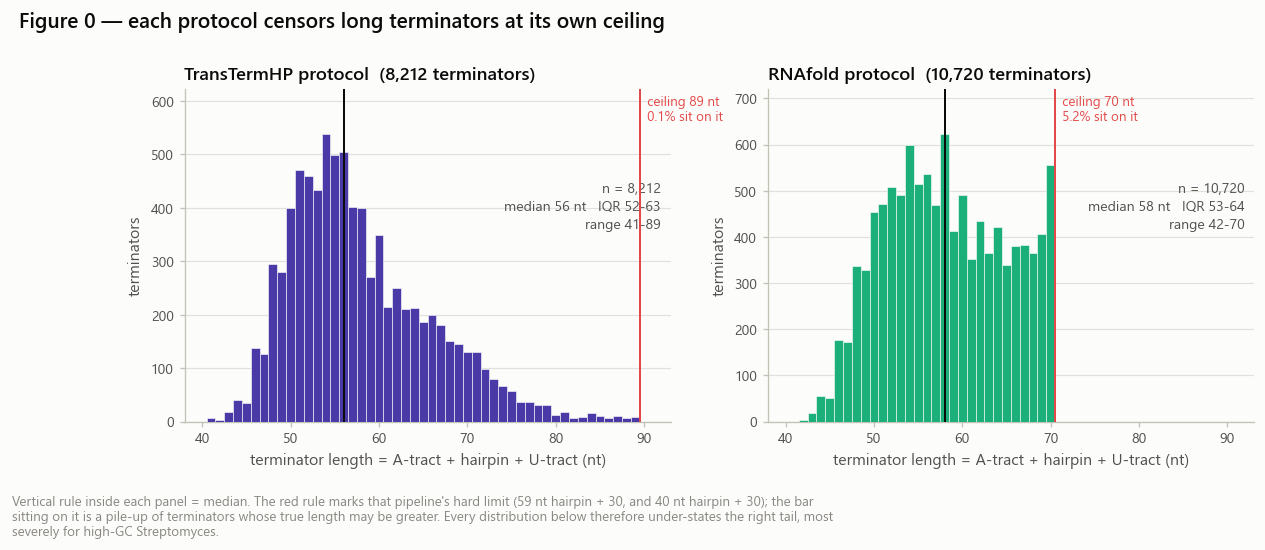

In [10]:
def hist_int(ax, values, color, bins=None, label=None, alpha=1.0):
    v = pd.to_numeric(pd.Series(values), errors="coerce").dropna().to_numpy()
    if bins is None:
        lo, hi = int(np.floor(v.min())), int(np.ceil(v.max()))
        bins = np.arange(lo - 0.5, hi + 1.5, 1)
    ax.hist(v, bins=bins, color=color, alpha=alpha, label=label,
            edgecolor=SURFACE, linewidth=0.35, zorder=3)
    return v


def median_rule(ax, med, label=None, color=INK):
    # A near-black hairline reads as an annotation, not as another bar.
    ax.axvline(med, color=color, lw=1.2, zorder=6)
    if label:
        ax.annotate(label, xy=(med, 1.0), xycoords=("data", "axes fraction"),
                    xytext=(4, -2), textcoords="offset points",
                    fontsize=8.5, color=INK, va="top", fontweight="semibold")


def annotate_stats(ax, v, y=0.97, prefix=""):
    q1, med, q3 = np.percentile(v, [25, 50, 75])
    txt = "{}n = {:,}\nmedian {:.0f} nt   IQR {:.0f}-{:.0f}\nrange {:.0f}-{:.0f}".format(
        prefix, len(v), med, q1, q3, v.min(), v.max())
    ax.text(0.98, y, txt, transform=ax.transAxes, ha="right", va="top",
            fontsize=8.5, color=INK2, linespacing=1.5)
    median_rule(ax, med)
    return q1, med, q3


PIPE_COLOR = {"TransTermHP": SER["violet"], "RNAfold": SER["aqua"]}
XLIM = (38, 93)          # shared x-range for terminator length

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.6))

for ax, (name, col, cap) in zip(axes, [("TransTermHP", "tt_terminator_len", 89),
                                       ("RNAfold", "rf_terminator_len", 70)]):
    v = hist_int(ax, df[col], PIPE_COLOR[name])
    ax.set_ylim(0, ax.get_ylim()[1] * 1.10)
    at_cap = (v >= cap).mean() * 100
    ax.axvline(cap + 0.5, color=SER["red"], lw=1.2, zorder=5)
    ax.text(cap + 0.5, ax.get_ylim()[1] * 0.98,
            "  ceiling {} nt\n  {:.1f}% sit on it".format(cap, at_cap),
            fontsize=8, color=SER["red"], va="top", ha="left")
    annotate_stats(ax, v, y=0.72)
    ax.set_title("{} protocol  ({:,} terminators)".format(name, len(v)))
    ax.set_xlabel("terminator length = A-tract + hairpin + U-tract (nt)")
    ax.set_ylabel("terminators")
    ax.set_xlim(*XLIM)
    style_axes(ax, grid="y")

fig.suptitle("Figure 0 — each protocol censors long terminators at its own ceiling",
             x=0.005, ha="left", fontsize=12.5, fontweight="semibold", y=1.06)
fig_note(fig, "Vertical rule inside each panel = median. The red rule marks that pipeline's hard limit "
              "(59 nt hairpin + 30, and 40 nt hairpin + 30); the bar sitting on it is a pile-up of "
              "terminators whose true length may be greater. Every distribution below therefore "
              "under-states the right tail, most severely for high-GC Streptomyces.", y=-0.06)
save(fig, "fig00_pipeline_censoring")
plt.show()

In [11]:
# table view for Figure 0
pipe_tbl = pd.DataFrame({
    "TransTermHP": df["tt_terminator_len"].describe(),
    "RNAfold": df["rf_terminator_len"].describe(),
    "coalesced (terminator_len)": df["terminator_len"].describe(),
}).round(2)
pipe_tbl.loc["% on the ceiling"] = [
    round(df["tt_terminator_len"].ge(89).sum() / df["tt_terminator_len"].notna().sum() * 100, 2),
    round(df["rf_terminator_len"].ge(70).sum() / df["rf_terminator_len"].notna().sum() * 100, 2),
    np.nan]
pipe_tbl.to_csv(TAB / "pipeline_length_summary.csv")
pipe_tbl

,TransTermHP,RNAfold,coalesced (terminator_len)
count,8212.00,10720.00,11769.00
mean,57.92,58.20,58.82
std,7.96,6.86,7.65
min,41.00,42.00,41.00
25%,52.00,53.00,53.00
50%,56.00,58.00,58.00
75%,63.00,64.00,64.00
max,89.00,70.00,89.00
% on the ceiling,0.10,5.19,NaN


### 3c. Termination efficiency in Supplementary Table 2 is partly corrupted by Excel

183 of the 3,561 reported TE values are stored as **date serials in 2023** (44,927–45,199)
instead of percentages. They are text values such as `25.7` that Excel — in a `DD.MM`
locale — reinterpreted as *25 July 2023*. The reading is unambiguous: a one-decimal string
has only one digit after the point, yet the integer parts of the recovered dates run up to
31, so the first number can only be the day. §1 therefore restores them as
`day + month/10`. Left untouched they would silently poison any model trained on this
column.

53 further values are **negative**; those are genuine TERMITe output (the estimate goes
below zero when downstream RNA-seq coverage exceeds upstream) and are kept as-is. The
length columns are unaffected — they are sequences, not numbers.

saved: outputs\terminator_length\figures\fig00b_te_excel_artefact.png


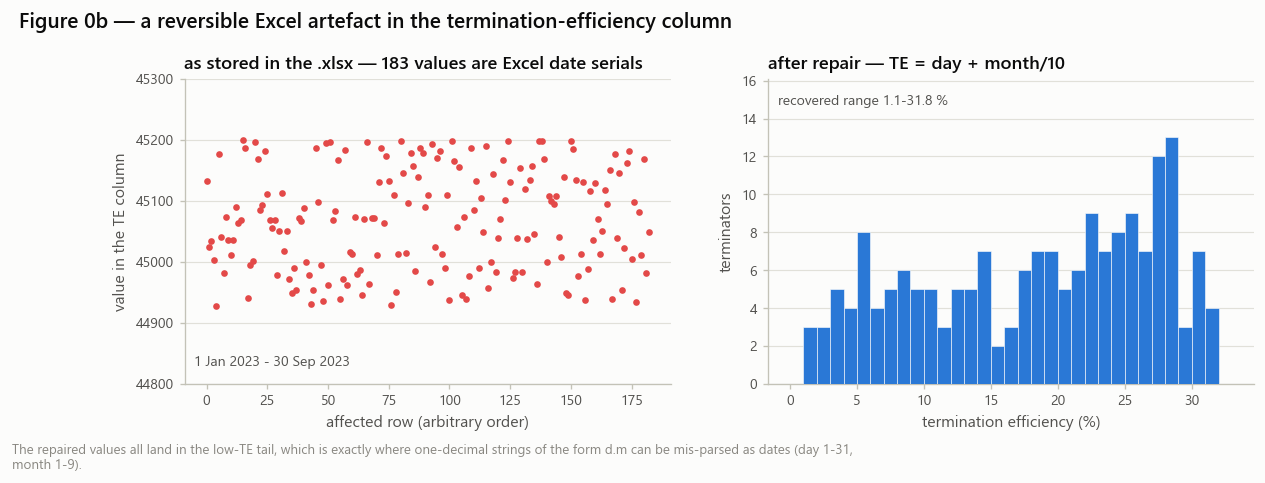

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.3))

ax = axes[0]
ax.scatter(np.arange(int(corrupt.sum())), te_raw[corrupt].to_numpy(), s=9,
           color=SER["red"], zorder=3)
ax.set_title("as stored in the .xlsx — 183 values are Excel date serials")
ax.set_xlabel("affected row (arbitrary order)")
ax.set_ylabel("value in the TE column")
ax.set_ylim(44800, 45300)
style_axes(ax, grid="y")
ax.text(0.02, 0.06, "1 Jan 2023 - 30 Sep 2023", transform=ax.transAxes,
        fontsize=8.5, color=INK2)

ax = axes[1]
hist_int(ax, df.loc[corrupt, "te_pct"], SER["blue"], bins=np.arange(0, 34, 1))
ax.set_title("after repair — TE = day + month/10")
ax.set_xlabel("termination efficiency (%)")
ax.set_ylabel("terminators")
style_axes(ax, grid="y")
ax.set_ylim(0, ax.get_ylim()[1] * 1.18)
ax.text(0.02, 0.95, "recovered range {:.1f}-{:.1f} %".format(
    df.loc[corrupt, "te_pct"].min(), df.loc[corrupt, "te_pct"].max()),
    transform=ax.transAxes, ha="left", va="top", fontsize=8.5, color=INK2)

fig.suptitle("Figure 0b — a reversible Excel artefact in the termination-efficiency column",
             x=0.005, ha="left", fontsize=12.5, fontweight="semibold", y=1.05)
fig_note(fig, "The repaired values all land in the low-TE tail, which is exactly where one-decimal "
              "strings of the form d.m can be mis-parsed as dates (day 1-31, month 1-9).", y=-0.04)
save(fig, "fig00b_te_excel_artefact")
plt.show()

## 4. Overall distribution and range of terminator length

The headline answer to "how long is an intrinsic terminator?", with the A-tract, hairpin
and U-tract added together.

saved: outputs\terminator_length\figures\fig01_overall_distribution.png


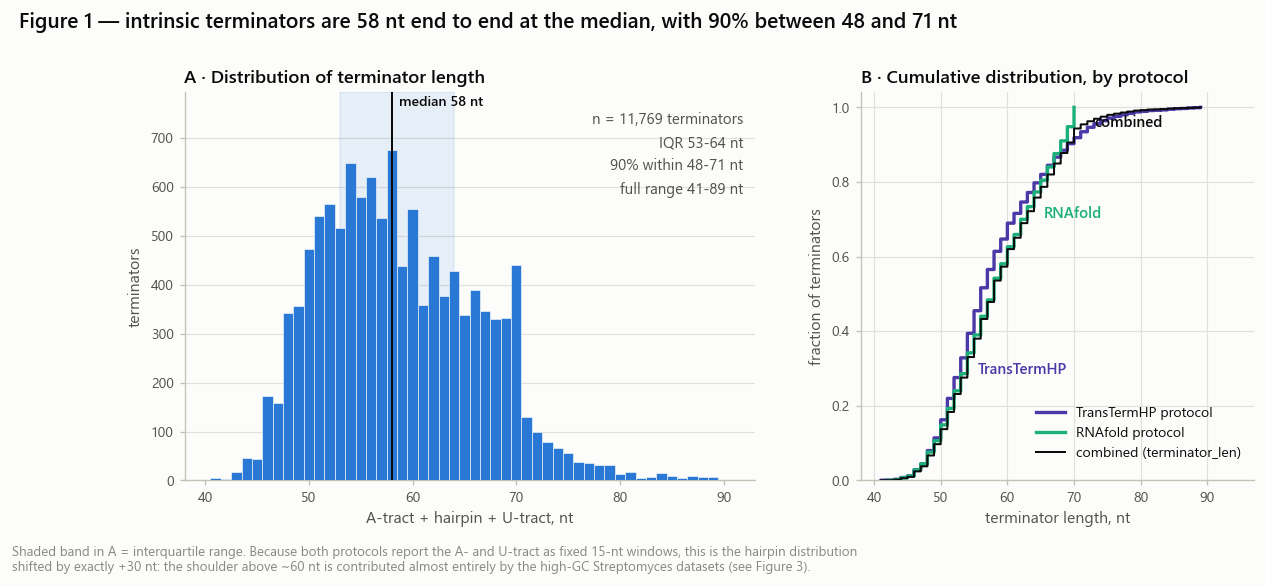

In [13]:
v_all = df["terminator_len"].dropna().to_numpy()
q = np.percentile(v_all, [1, 5, 25, 50, 75, 95, 99])

fig = plt.figure(figsize=(11.5, 4.2))
gs = fig.add_gridspec(1, 2, width_ratios=[1.45, 1], wspace=0.22)

# --- A: histogram --------------------------------------------------------
ax = fig.add_subplot(gs[0, 0])
hist_int(ax, v_all, SER["blue"])
ax.set_ylim(0, ax.get_ylim()[1] * 1.12)
ax.axvspan(q[2], q[4], color=SER["blue"], alpha=0.10, zorder=1)
median_rule(ax, q[3], "median {:.0f} nt".format(q[3]))
ax.text(0.98, 0.95,
        "n = {:,} terminators\nIQR {:.0f}-{:.0f} nt\n90% within {:.0f}-{:.0f} nt\nfull range {:.0f}-{:.0f} nt".format(
            len(v_all), q[2], q[4], q[1], q[5], v_all.min(), v_all.max()),
        transform=ax.transAxes, ha="right", va="top", fontsize=9, color=INK2, linespacing=1.6)
ax.set_title("A · Distribution of terminator length")
ax.set_xlabel("A-tract + hairpin + U-tract, nt")
ax.set_ylabel("terminators")
ax.set_xlim(*XLIM)
style_axes(ax, grid="y")

# --- B: ECDF by protocol -------------------------------------------------
ax = fig.add_subplot(gs[0, 1])
for name, col, at in [("TransTermHP", "tt_terminator_len", 0.30),
                      ("RNAfold", "rf_terminator_len", 0.72)]:
    v = df[col].dropna().sort_values().to_numpy()
    y = np.arange(1, len(v) + 1) / len(v)
    ax.step(v, y, where="post", color=PIPE_COLOR[name], lw=2, zorder=3)
    ax.annotate(name, xy=(v[int(len(v) * at)], at), xytext=(10, -1),
                textcoords="offset points", color=PIPE_COLOR[name],
                fontsize=9, fontweight="semibold", va="center")
v = np.sort(v_all)
ax.step(v, np.arange(1, len(v) + 1) / len(v), where="post", color=INK, lw=1.2, zorder=4)
ax.annotate("combined", xy=(v[int(len(v) * 0.95)], 0.95), xytext=(8, 2),
            textcoords="offset points", color=INK, fontsize=9, fontweight="semibold", va="center")
ax.set_title("B · Cumulative distribution, by protocol")
ax.set_xlabel("terminator length, nt")
ax.set_ylabel("fraction of terminators")
ax.set_xlim(38, 97); ax.set_ylim(0, 1.04)
ax.legend(handles=[Line2D([], [], color=PIPE_COLOR["TransTermHP"], lw=2, label="TransTermHP protocol"),
                   Line2D([], [], color=PIPE_COLOR["RNAfold"], lw=2, label="RNAfold protocol"),
                   Line2D([], [], color=INK, lw=1.2, label="combined (terminator_len)")],
          loc="lower right", bbox_to_anchor=(1.0, 0.02))
style_axes(ax, grid="both")

fig.suptitle("Figure 1 — intrinsic terminators are {:.0f} nt end to end at the median, "
             "with 90% between {:.0f} and {:.0f} nt".format(q[3], q[1], q[5]),
             x=0.005, ha="left", fontsize=12.5, fontweight="semibold", y=1.04)
fig_note(fig, "Shaded band in A = interquartile range. Because both protocols report the A- and U-tract "
              "as fixed 15-nt windows, this is the hairpin distribution shifted by exactly +30 nt: the "
              "shoulder above ~60 nt is contributed almost entirely by the high-GC Streptomyces datasets "
              "(see Figure 3).", y=-0.02)
save(fig, "fig01_overall_distribution")
plt.show()

In [14]:
# table view for Figure 1 - every length variant, both protocols
def describe_len(s):
    v = pd.to_numeric(s, errors="coerce").dropna().to_numpy()
    p = np.percentile(v, [5, 25, 50, 75, 95])
    return pd.Series({"n": len(v), "min": v.min(), "p5": p[0], "Q1": p[1], "median": p[2],
                      "Q3": p[3], "p95": p[4], "max": v.max(),
                      "mean": round(v.mean(), 2), "sd": round(v.std(ddof=1), 2)})

variants = {
    "TransTermHP  A+hairpin+U (as annotated)": df["tt_terminator_len"],
    "RNAfold      A+hairpin+U (as annotated)": df["rf_terminator_len"],
    "combined     A+hairpin+U (as annotated)": df["terminator_len"],
    "TransTermHP  A+hairpin+U (measured runs)": df["tt_terminator_len_seq"],
    "RNAfold      A+hairpin+U (measured runs)": df["rf_terminator_len_seq"],
    "combined     A+hairpin+U (measured runs)": df["terminator_len_seq"],
    "combined     hairpin only": df["hairpin_len"],
}
overall = pd.DataFrame({k: describe_len(v) for k, v in variants.items()}).T
overall.to_csv(TAB / "terminator_length_variants.csv")
overall

,n,min,p5,Q1,median,Q3,p95,max,mean,sd
TransTermHP A+hairpin+U (as annotated),8212.0,41.0,48.0,52.0,56.0,63.0,73.0,89.0,57.92,7.96
RNAfold A+hairpin+U (as annotated),10720.0,42.0,48.0,53.0,58.0,64.0,70.0,70.0,58.20,6.86
combined A+hairpin+U (as annotated),11769.0,41.0,48.0,53.0,58.0,64.0,71.0,89.0,58.82,7.65
TransTermHP A+hairpin+U (measured runs),8212.0,17.0,25.0,30.0,34.0,39.0,48.0,69.0,34.79,7.11
RNAfold A+hairpin+U (measured runs),10720.0,13.0,23.0,29.0,33.0,38.0,43.0,54.0,33.39,5.98
combined A+hairpin+U (measured runs),11769.0,14.0,24.0,30.0,34.0,39.0,46.0,69.0,34.41,6.85
combined hairpin only,11769.0,11.0,18.0,23.0,28.0,34.0,41.0,59.0,28.82,7.65


### Do the two protocols agree?

7,163 terminators are annotated by **both** protocols, so their length estimates can be
compared directly on the same elements.

saved: outputs\terminator_length\figures\fig01b_protocol_agreement.png


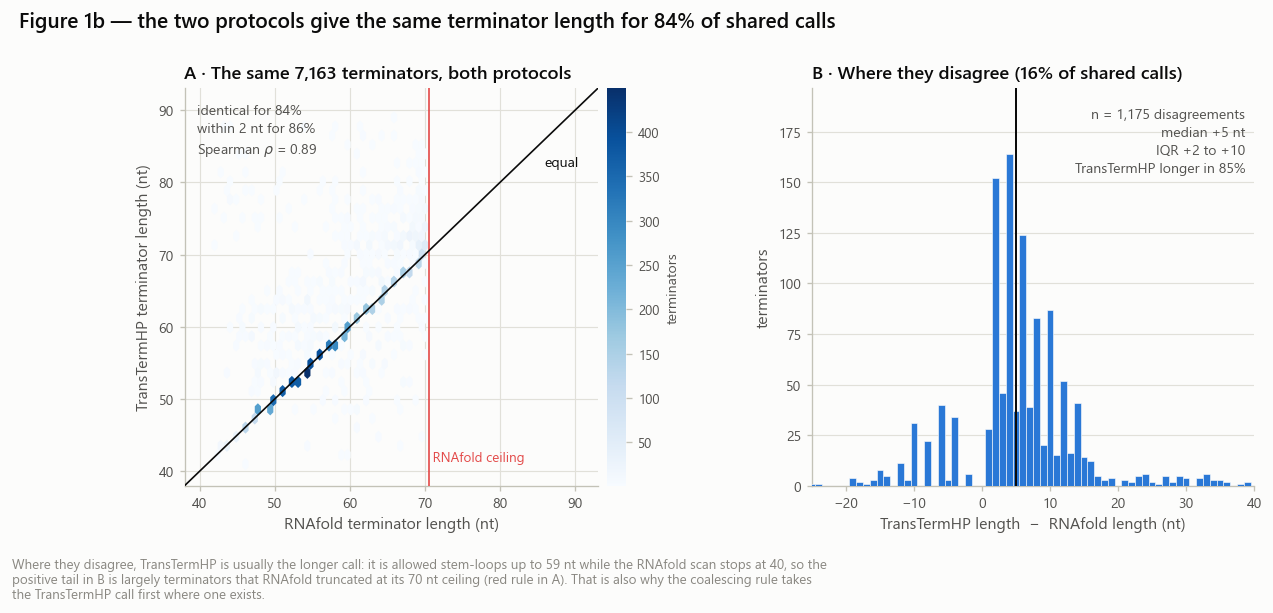

In [15]:
both = df["tt_terminator_len"].notna() & df["rf_terminator_len"].notna()
x = df.loc[both, "rf_terminator_len"].to_numpy(float)
y = df.loc[both, "tt_terminator_len"].to_numpy(float)
d = y - x

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.3), gridspec_kw={"wspace": 0.42})

ax = axes[0]
hb = ax.hexbin(x, y, gridsize=34, mincnt=1, cmap="Blues", linewidths=0)
lims = (38, 93)
ax.plot(lims, lims, color=INK, lw=1.0, zorder=5)
ax.annotate("equal", xy=(lims[1] - 8, lims[1] - 8), xytext=(4, -12),
            textcoords="offset points", fontsize=8.5, color=INK)
ax.axvline(70.5, color=SER["red"], lw=1.0, zorder=4)
ax.text(70.5, 41, " RNAfold ceiling", fontsize=8, color=SER["red"], va="bottom")
ax.set_xlim(*lims); ax.set_ylim(*lims)
ax.set_xlabel("RNAfold terminator length (nt)")
ax.set_ylabel("TransTermHP terminator length (nt)")
ax.set_title("A · The same {:,} terminators, both protocols".format(int(both.sum())))
cb = fig.colorbar(hb, ax=ax, pad=0.02, fraction=0.045)
cb.set_label("terminators", fontsize=8.5, color=INK2)
cb.ax.tick_params(labelsize=8, color=AXIS)
cb.outline.set_visible(False)
ax.text(0.03, 0.96, "identical for {:.0f}%\nwithin 2 nt for {:.0f}%\nSpearman $\\rho$ = {:.2f}".format(
    100 * (d == 0).mean(), 100 * (np.abs(d) <= 2).mean(),
    stats.spearmanr(x, y).statistic),
    transform=ax.transAxes, va="top", fontsize=8.5, color=INK2, linespacing=1.5)
style_axes(ax, grid="both")

ax = axes[1]
# the 0-bar holds 84% of the mass and would flatten everything else - show the disagreements
dd = d[d != 0]
hist_int(ax, dd, SER["blue"], bins=np.arange(-30.5, 45.5, 1))
ax.set_ylim(0, ax.get_ylim()[1] * 1.14)
median_rule(ax, np.median(dd))
ax.set_xlim(-25, 40)
ax.set_xlabel("TransTermHP length  −  RNAfold length (nt)")
ax.set_ylabel("terminators")
ax.set_title("B · Where they disagree ({:.0f}% of shared calls)".format(100 * (d != 0).mean()))
ax.text(0.98, 0.95, "n = {:,} disagreements\nmedian {:+.0f} nt\nIQR {:+.0f} to {:+.0f}\n"
                    "TransTermHP longer in {:.0f}%".format(
    len(dd), np.median(dd), np.percentile(dd, 25), np.percentile(dd, 75), 100 * (dd > 0).mean()),
    transform=ax.transAxes, ha="right", va="top", fontsize=8.5, color=INK2, linespacing=1.5)
style_axes(ax, grid="y")

fig.suptitle("Figure 1b — the two protocols give the same terminator length for 84% of shared calls",
             x=0.005, ha="left", fontsize=12.5, fontweight="semibold", y=1.03)
fig_note(fig, "Where they disagree, TransTermHP is usually the longer call: it is allowed stem-loops up "
              "to 59 nt while the RNAfold scan stops at 40, so the positive tail in B is largely "
              "terminators that RNAfold truncated at its 70 nt ceiling (red rule in A). That is also why "
              "the coalescing rule takes the TransTermHP call first where one exists.", y=-0.03)
save(fig, "fig01b_protocol_agreement")
plt.show()

## 5. Where that length comes from — the parts of the terminator

The 30 nt of A- and U-tract are fixed by the reporting format, so all real variation in
terminator length lives in the hairpin, and within the hairpin almost all of it lives in
the stem. The bottom row shows what the flanks look like when they are *measured* from the
sequence rather than taken as fixed windows.

saved: outputs\terminator_length\figures\fig02_terminator_anatomy.png


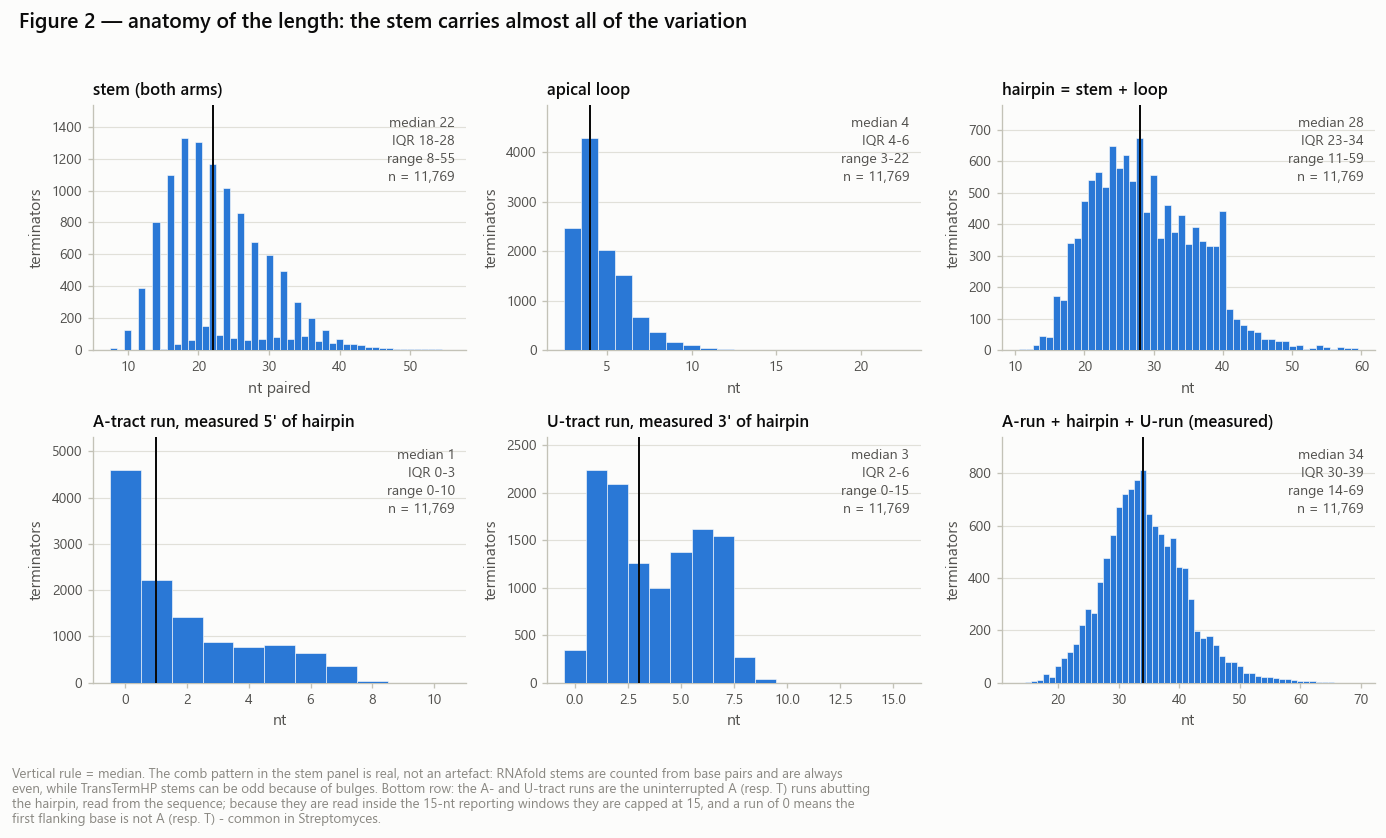

In [16]:
PARTS = [
    ("stem_nt",            "stem (both arms)",                     "nt paired"),
    ("loop_nt",            "apical loop",                          "nt"),
    ("hairpin_len",        "hairpin = stem + loop",                "nt"),
    ("a_run",              "A-tract run, measured 5' of hairpin",  "nt"),
    ("u_run",              "U-tract run, measured 3' of hairpin",  "nt"),
    ("terminator_len_seq", "A-run + hairpin + U-run (measured)",   "nt"),
]

fig, axes = plt.subplots(2, 3, figsize=(11.5, 6.0))
for ax, (col, title, unit) in zip(axes.ravel(), PARTS):
    v = df[col].dropna().to_numpy()
    hist_int(ax, v, SER["blue"])
    ax.set_ylim(0, ax.get_ylim()[1] * 1.10)
    med = np.median(v)
    median_rule(ax, med)
    q1, q3 = np.percentile(v, [25, 75])
    ax.text(0.97, 0.95, "median {:.0f}\nIQR {:.0f}-{:.0f}\nrange {:.0f}-{:.0f}\nn = {:,}".format(
        med, q1, q3, v.min(), v.max(), len(v)),
        transform=ax.transAxes, ha="right", va="top", fontsize=8.5, color=INK2, linespacing=1.5)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel(unit)
    ax.set_ylabel("terminators")
    style_axes(ax, grid="y")

fig.suptitle("Figure 2 — anatomy of the length: the stem carries almost all of the variation",
             x=0.005, ha="left", fontsize=12.5, fontweight="semibold", y=1.02)
fig.tight_layout()
fig_note(fig, "Vertical rule = median. The comb pattern in the stem panel is real, not an artefact: "
              "RNAfold stems are counted from base pairs and are always even, while TransTermHP stems "
              "can be odd because of bulges. Bottom row: the A- and U-tract runs are the uninterrupted "
              "A (resp. T) runs abutting the hairpin, read from the sequence; because they are read "
              "inside the 15-nt reporting windows they are capped at 15, and a run of 0 means the first "
              "flanking base is not A (resp. T) - common in Streptomyces.", y=-0.03)
save(fig, "fig02_terminator_anatomy")
plt.show()

In [17]:
# table view for Figure 2
parts_tbl = (df[[c for c, _, _ in PARTS] + ["terminator_len"]]
             .describe(percentiles=[.05, .25, .5, .75, .95]).T
             .rename(columns={"50%": "median"}).round(2))
parts_tbl.to_csv(TAB / "terminator_parts_summary.csv")
parts_tbl

,count,mean,std,min,5%,25%,median,75%,95%,max
stem_nt,11769.0,23.12,7.36,8.0,14.0,18.0,22.0,28.0,36.0,55.0
loop_nt,11769.0,4.74,1.71,3.0,3.0,4.0,4.0,6.0,8.0,22.0
hairpin_len,11769.0,28.82,7.65,11.0,18.0,23.0,28.0,34.0,41.0,59.0
a_run,11769.0,1.85,2.12,0.0,0.0,0.0,1.0,3.0,6.0,10.0
u_run,11769.0,3.75,2.29,0.0,1.0,2.0,3.0,6.0,7.0,15.0
terminator_len_seq,11769.0,34.41,6.85,14.0,24.0,30.0,34.0,39.0,46.0,69.0
terminator_len,11769.0,58.82,7.65,41.0,48.0,53.0,58.0,64.0,71.0,89.0


In [18]:
# ---- statistics & plotting helpers ------------------------------------
def cliffs_delta(a, b):
    # Non-parametric effect size in [-1, 1], derived from the Mann-Whitney U statistic.
    a = np.asarray(a, float); b = np.asarray(b, float)
    U = stats.mannwhitneyu(a, b, alternative="two-sided").statistic
    return 2.0 * U / (len(a) * len(b)) - 1.0

def delta_label(d):
    a = abs(d)
    return "negligible" if a < 0.147 else "small" if a < 0.33 else "medium" if a < 0.474 else "large"

def compare(a, b, name_a="A", name_b="B"):
    a = pd.Series(a).dropna().to_numpy(float); b = pd.Series(b).dropna().to_numpy(float)
    u = stats.mannwhitneyu(a, b, alternative="two-sided")
    d = cliffs_delta(a, b)
    return {"group_a": name_a, "n_a": len(a), "median_a": float(np.median(a)),
            "group_b": name_b, "n_b": len(b), "median_b": float(np.median(b)),
            "median_diff": float(np.median(a) - np.median(b)),
            "MWU_p": u.pvalue, "cliffs_delta": round(d, 3), "effect": delta_label(d)}

def boxes(ax, data, positions, color, widths=0.62, horizontal=True):
    # matplotlib renamed vert -> orientation in 3.10; support both.
    kw = dict(positions=positions, widths=widths, patch_artist=True, showfliers=False,
              zorder=3, medianprops=dict(color=SURFACE, lw=1.5),
              whiskerprops=dict(color=color, lw=1.0), capprops=dict(color=color, lw=1.0))
    try:
        bp = ax.boxplot(data, orientation="horizontal" if horizontal else "vertical", **kw)
    except TypeError:
        bp = ax.boxplot(data, vert=not horizontal, **kw)
    for patch in bp["boxes"]:
        patch.set_facecolor(color); patch.set_edgecolor(SURFACE); patch.set_linewidth(1.2)
    return bp

LEN = "terminator_len"                      # the primary variable everywhere below
LEN_LABEL = "terminator length = A-tract + hairpin + U-tract, nt"

## 6. Species-resolved distributions

The atlas holds **17 datasets covering 13 organisms** — *B. subtilis* appears four times
and *E. coli* twice, from different studies. Both levels are shown: dataset first (which
also exposes the TE split), then organism. Per-protocol medians are carried in the tables
alongside the combined value.

In [19]:
# ---- per-dataset summary ----------------------------------------------
def summarise(frame, key, value=LEN):
    g = frame.groupby(key)[value]
    out = pd.DataFrame({"n": g.size(), "min": g.min(), "Q1": g.quantile(.25),
                        "median": g.median(), "Q3": g.quantile(.75),
                        "p95": g.quantile(.95), "max": g.max(),
                        "mean": g.mean(), "sd": g.std()})
    out["IQR"] = out["Q3"] - out["Q1"]
    # the same quantity computed inside each protocol on its own
    for pre, lab in [("tt", "TransTermHP"), ("rf", "RNAfold")]:
        gg = frame.groupby(key)[pre + "_terminator_len"]
        out["n_" + lab] = gg.count()
        out["median_" + lab] = gg.median()
    out["median_measured"] = frame.groupby(key)["terminator_len_seq"].median()
    return out.sort_values("median")

ds_stats = summarise(df, "dataset")
ds_stats = ds_stats.join(df.groupby("dataset")[["te_group", "protocol", "reference",
                                                "lineage", "species", "bioproject", "n_runs"]].first())
ds_stats["median_TE_%"] = df.groupby("dataset")["te_pct"].median().round(1)
ds_stats["context_GC_%"] = (df.groupby("dataset")["context_gc"].mean() * 100).round(1)
ds_stats.round(2).to_csv(TAB / "terminator_length_by_dataset.csv")
ds_stats.round(2)

,n,min,Q1,median,Q3,p95,max,mean,sd,IQR,n_TransTermHP,median_TransTermHP,n_RNAfold,median_RNAfold,median_measured,te_group,protocol,reference,lineage,species,bioproject,n_runs,median_TE_%,context_GC_%
dataset,,,,,,,,,,,,,,,,,,,,,,,,
Bacillus subtilis (a),635,41.0,51.0,54.0,57.50,66.0,78.0,54.97,5.58,6.50,569,54.0,564,54.0,33.0,TE measured,Mondal et al. 2016,Chabbra et al. 2022,Firmicutes,Bacillus subtilis,PRJNA792588,12,88.6,39.5
Bacillus subtilis (b),1165,41.0,51.0,54.0,58.00,66.0,84.0,55.12,5.83,7.00,1039,54.0,1005,54.0,33.0,TE measured,Mondal et al. 2016,Mandell et al. 2021,Firmicutes,Bacillus subtilis,PRJNA646522,8,92.7,39.5
Bacillus subtilis (c),984,41.0,51.0,54.0,58.00,66.0,79.0,54.97,5.57,7.00,885,54.0,867,54.0,33.0,no TE,Dar et al. 2016,Dar et al. 2016,Firmicutes,Bacillus subtilis,PRJEB12568,25,NaN,39.9
Bacillus subtilis (d),1214,41.0,51.0,54.0,58.00,66.0,84.0,55.10,5.84,7.00,1080,54.0,1053,54.0,33.0,TE measured,Mondal et al. 2016,Mondal et al. 2016,Firmicutes,Bacillus subtilis,PRJNA278818,12,96.7,39.7
Escherichia coli (a),691,43.0,50.0,54.0,58.50,66.0,86.0,54.60,6.71,8.50,530,52.0,650,53.0,29.0,TE measured,Mondal et al. 2016,this study,Proteobacteria,Escherichia coli,PRJNA906280,3,83.2,48.0
Escherichia coli (b),957,43.0,50.0,55.0,60.00,67.0,81.0,55.47,6.78,10.00,661,53.0,904,54.0,30.0,no TE,Dar et al. 2016,Choe et al. 2022,Proteobacteria,Escherichia coli,PRJEB36932,3,NaN,48.8
Synechocystis sp.,165,42.0,53.0,57.0,62.00,70.0,89.0,57.52,7.81,9.00,119,55.0,154,57.0,32.0,no TE,Dar et al. 2016,Cho et al. 2021,Cyanobacteria,Synechocystis sp.,PRJNA666973,2,NaN,45.2
Zymomonas mobilis,206,45.0,54.0,57.0,62.75,72.5,89.0,59.00,7.41,8.75,165,57.0,189,57.0,35.0,no TE,Dar et al. 2016,Vera et al. 2020,Proteobacteria,Zymomonas mobilis,PRJNA587699,19,NaN,41.0
Listeria monocytogenes,862,41.0,54.0,58.0,63.00,72.0,87.0,58.66,6.94,9.00,797,57.0,754,58.0,37.0,no TE,Dar et al. 2016,Dar et al. 2016,Firmicutes,Listeria monocytogenes,PRJEB12568,24,NaN,33.3


saved: outputs\terminator_length\figures\fig03_ridgeline_by_dataset.png


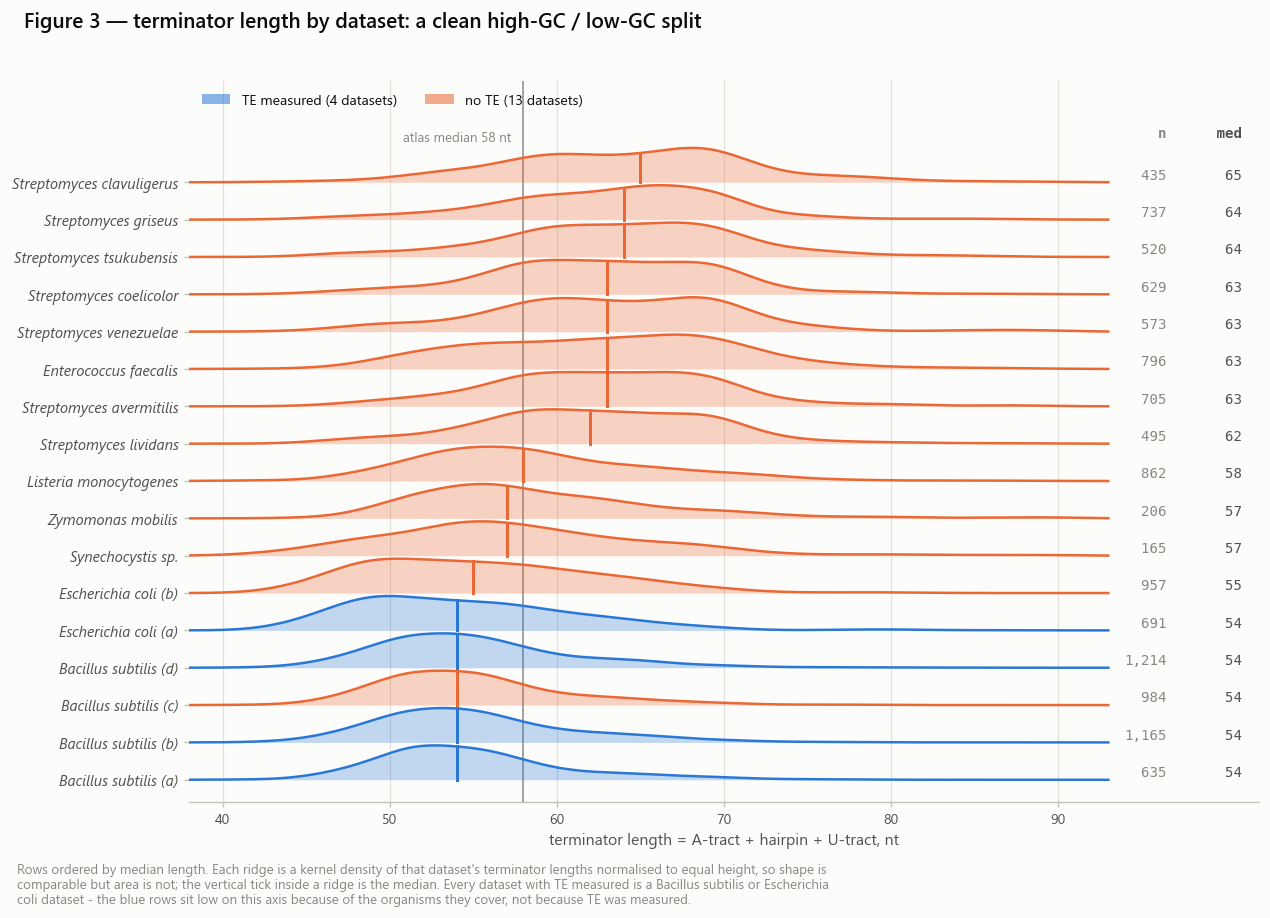

In [20]:
# ---- Figure 3: ridgeline by dataset, coloured by TE availability -------
order = ds_stats.index.tolist()                       # ascending median
xs = np.linspace(38, 93, 400)

fig, ax = plt.subplots(figsize=(11.5, 7.8))
for i, name in enumerate(order):
    v = df.loc[df["dataset"] == name, LEN].dropna().to_numpy(float)
    c = TE_COLOR[ds_stats.loc[name, "te_group"]]
    kde = stats.gaussian_kde(v, bw_method=0.30)
    dens = kde(xs)
    peak = dens.max()
    y = dens / peak * 0.92
    z = 3 + i * 0.01
    ax.fill_between(xs, i, i + y, color=c, alpha=0.28, lw=0, zorder=z)
    ax.plot(xs, i + y, color=c, lw=1.5, zorder=z + 0.004)
    med = float(ds_stats.loc[name, "median"])
    ax.plot([med, med], [i, i + float(kde(med)[0]) / peak * 0.92],
            color=c, lw=1.8, zorder=z + 0.006)
    ax.text(96.5, i + 0.2, "{:>5,}".format(int(ds_stats.loc[name, "n"])),
            fontsize=8.5, color=MUTED, va="center", ha="right", family="monospace")
    ax.text(101.0, i + 0.2, "{:>4.0f}".format(med),
            fontsize=8.5, color=INK2, va="center", ha="right", family="monospace")

ax.set_yticks(np.arange(len(order)))
ax.set_yticklabels(order, fontsize=9, fontstyle="italic")
ax.set_ylim(-0.6, len(order) + 1.7)
ax.set_xlim(38, 102)
ax.set_xticks(np.arange(40, 95, 10))
ax.set_xlabel(LEN_LABEL)
ax.text(96.5, len(order) + 0.2, "    n", fontsize=8.5, color=MUTED, ha="right",
        family="monospace", fontweight="semibold")
ax.text(101.0, len(order) + 0.2, " med", fontsize=8.5, color=INK2, ha="right",
        family="monospace", fontweight="semibold")
gm = df[LEN].median()
ax.axvline(gm, color=MUTED, lw=0.9, zorder=2)
ax.text(gm - 0.7, len(order) + 0.2, "atlas median {:.0f} nt".format(gm),
        fontsize=8, color=MUTED, ha="right", va="center")
ax.legend(handles=[Patch(facecolor=TE_COLOR[TE_MEASURED], alpha=0.55, label="TE measured (4 datasets)"),
                   Patch(facecolor=TE_COLOR[TE_NONE], alpha=0.55, label="no TE (13 datasets)")],
          loc="upper left", bbox_to_anchor=(0.0, 1.0), ncol=2)
style_axes(ax, grid="x", hide=("top", "right", "left"))

fig.suptitle("Figure 3 — terminator length by dataset: a clean high-GC / low-GC split",
             x=0.005, ha="left", fontsize=12.5, fontweight="semibold", y=0.955)
fig_note(fig, "Rows ordered by median length. Each ridge is a kernel density of that dataset's "
              "terminator lengths normalised to equal height, so shape is comparable but area is not; "
              "the vertical tick inside a ridge is the median. Every dataset with TE measured is a "
              "Bacillus subtilis or Escherichia coli dataset - the blue rows sit low on this axis "
              "because of the organisms they cover, not because TE was measured.", y=0.045)
save(fig, "fig03_ridgeline_by_dataset")
plt.show()

saved: outputs\terminator_length\figures\fig04_by_species_and_gc.png


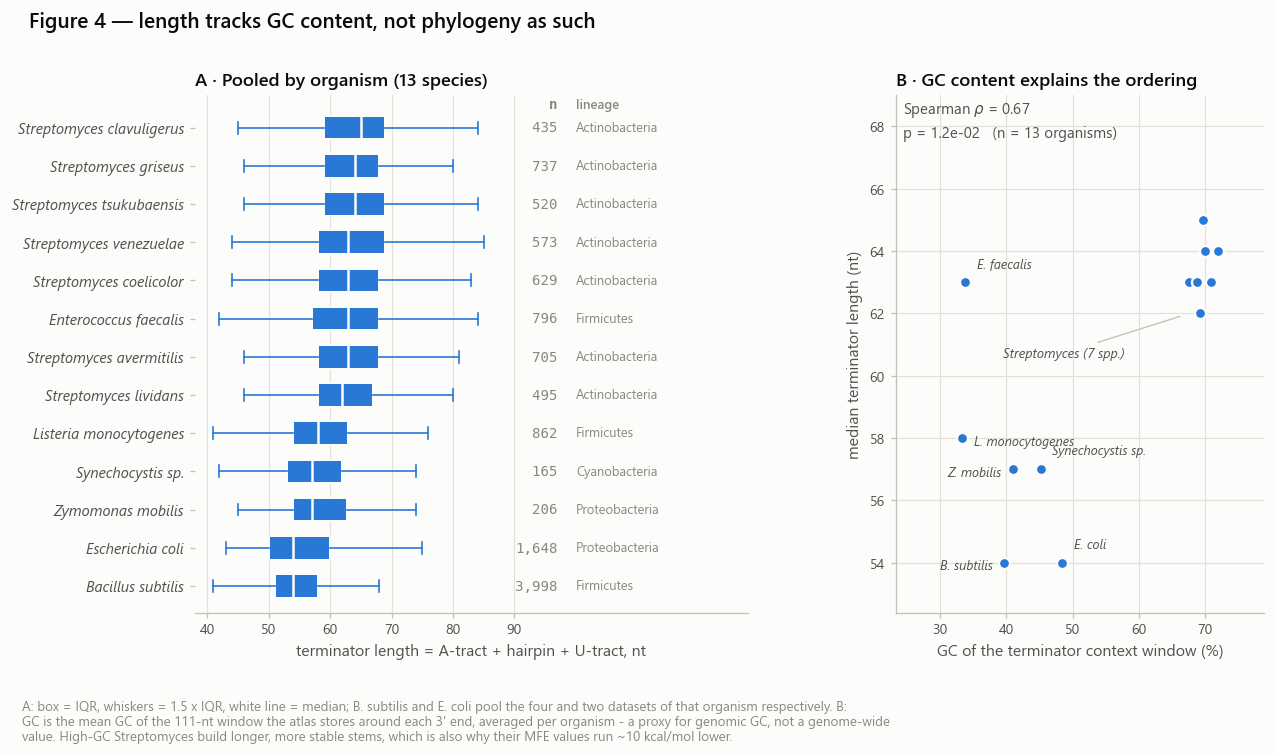

In [21]:
# ---- Figure 4: organism level, and the GC driver ----------------------
sp_stats = summarise(df, "species").join(df.groupby("species")[["lineage"]].first())
sp_stats["context_GC_%"] = (df.groupby("species")["context_gc"].mean() * 100).round(1)
sp_stats["n_datasets"] = df.groupby("species")["dataset"].nunique()
sp_stats.round(2).to_csv(TAB / "terminator_length_by_species.csv")

sp_order = sp_stats.index.tolist()
data = [df.loc[df["species"] == s, LEN].dropna().to_numpy(float) for s in sp_order]

fig = plt.figure(figsize=(11.5, 5.6))
gs = fig.add_gridspec(1, 2, width_ratios=[1.5, 1], wspace=0.32)

ax = fig.add_subplot(gs[0, 0])
boxes(ax, data, positions=np.arange(len(sp_order)), color=SER["blue"])
for i, (s, v) in enumerate(zip(sp_order, data)):
    ax.text(97.0, i, "{:>5,}".format(len(v)), fontsize=8.5, color=MUTED,
            va="center", ha="right", family="monospace")
    ax.text(100.0, i, sp_stats.loc[s, "lineage"], fontsize=7.8, color=MUTED, va="center")
ax.set_yticks(np.arange(len(sp_order)))
ax.set_yticklabels(sp_order, fontsize=9, fontstyle="italic")
ax.set_xlim(38, 128)
ax.set_ylim(-0.7, len(sp_order) - 0.15)
ax.set_xticks(np.arange(40, 95, 10))
ax.set_xlabel(LEN_LABEL)
ax.text(97.0, len(sp_order) - 0.5, "    n", fontsize=8.5, color=MUTED, ha="right",
        family="monospace", fontweight="semibold")
ax.text(100.0, len(sp_order) - 0.5, "lineage", fontsize=7.8, color=MUTED, fontweight="semibold")
ax.set_title("A · Pooled by organism (13 species)")
style_axes(ax, grid="x", hide=("top", "right", "left"))

ax = fig.add_subplot(gs[0, 1])
is_strep = sp_stats.index.str.startswith("Streptomyces")
ax.scatter(sp_stats["context_GC_%"], sp_stats["median"], s=44, color=SER["blue"],
           edgecolor=SURFACE, linewidth=1.4, zorder=4)

def short_name(s):
    p = s.split()
    return s if p[-1] == "sp." else p[0][0] + ". " + " ".join(p[1:])

pts = sp_stats[~is_strep][["context_GC_%", "median"]].to_numpy(float)
for k, (s, r) in enumerate(sp_stats[~is_strep].iterrows()):
    x0, y0 = float(r["context_GC_%"]), float(r["median"])
    # if a neighbour sits just to the right at the same height, label leftwards instead
    crowded = any(0 < px - x0 < 9.5 and abs(py - y0) < 0.6 for px, py in pts)
    dx, ha = (-7, "right") if crowded else (7, "left")
    ax.annotate(short_name(s), (x0, y0), xytext=(dx, -4 if k % 2 == 0 else 9),
                textcoords="offset points", ha=ha,
                fontsize=7.8, color=INK2, style="italic")
cl = sp_stats[is_strep]
ax.annotate("Streptomyces (7 spp.)", xy=(cl["context_GC_%"].min(), cl["median"].min()),
            xytext=(-112, -26), textcoords="offset points", fontsize=8, color=INK2, style="italic",
            arrowprops=dict(arrowstyle="-", color=AXIS, lw=0.8, shrinkA=2, shrinkB=6))
rho, pv = stats.spearmanr(sp_stats["context_GC_%"], sp_stats["median"])
ax.text(0.02, 0.99, "Spearman $\\rho$ = {:.2f}\np = {:.1e}   (n = 13 organisms)".format(rho, pv),
        transform=ax.transAxes, va="top", fontsize=9, color=INK2, linespacing=1.5)
ax.set_xlim(sp_stats["context_GC_%"].min() - 10, sp_stats["context_GC_%"].max() + 7)
ax.set_ylim(sp_stats["median"].min() - 1.6, sp_stats["median"].max() + 4.0)
ax.set_xlabel("GC of the terminator context window (%)")
ax.set_ylabel("median terminator length (nt)")
ax.set_title("B · GC content explains the ordering")
style_axes(ax, grid="both")

fig.suptitle("Figure 4 — length tracks GC content, not phylogeny as such",
             x=0.005, ha="left", fontsize=12.5, fontweight="semibold", y=1.005)
fig_note(fig, "A: box = IQR, whiskers = 1.5 x IQR, white line = median; B. subtilis and E. coli pool the "
              "four and two datasets of that organism respectively. B: GC is the mean GC of the 111-nt "
              "window the atlas stores around each 3' end, averaged per organism - a proxy for genomic "
              "GC, not a genome-wide value. High-GC Streptomyces build longer, more stable stems, which "
              "is also why their MFE values run ~10 kcal/mol lower.", y=-0.02)
save(fig, "fig04_by_species_and_gc")
plt.show()

In [22]:
sp_stats.round(2)

,n,min,Q1,median,Q3,p95,max,mean,sd,IQR,n_TransTermHP,median_TransTermHP,n_RNAfold,median_RNAfold,median_measured,lineage,context_GC_%,n_datasets
species,,,,,,,,,,,,,,,,,,
Bacillus subtilis,3998,41.0,51.0,54.0,58.00,66.0,84.0,55.05,5.73,7.00,3573,54.0,3489,54.0,33.0,Firmicutes,39.7,4
Escherichia coli,1648,43.0,50.0,54.0,60.00,67.0,86.0,55.10,6.76,10.00,1191,53.0,1554,54.0,30.0,Proteobacteria,48.4,2
Zymomonas mobilis,206,45.0,54.0,57.0,62.75,72.5,89.0,59.00,7.41,8.75,165,57.0,189,57.0,35.0,Proteobacteria,41.0,1
Synechocystis sp.,165,42.0,53.0,57.0,62.00,70.0,89.0,57.52,7.81,9.00,119,55.0,154,57.0,32.0,Cyanobacteria,45.2,1
Listeria monocytogenes,862,41.0,54.0,58.0,63.00,72.0,87.0,58.66,6.94,9.00,797,57.0,754,58.0,37.0,Firmicutes,33.3,1
Streptomyces lividans,495,46.0,58.0,62.0,67.00,72.3,88.0,62.38,6.82,9.00,195,63.0,471,62.0,35.0,Actinobacteria,69.2,1
Streptomyces avermitilis,705,46.0,58.0,63.0,68.00,74.0,89.0,63.01,6.86,10.00,325,64.0,667,63.0,36.0,Actinobacteria,67.6,1
Enterococcus faecalis,796,42.0,57.0,63.0,68.00,75.0,89.0,62.86,7.63,11.00,666,63.0,673,63.0,41.0,Firmicutes,33.8,1
Streptomyces coelicolor,629,44.0,58.0,63.0,68.00,72.6,88.0,62.83,6.71,10.00,222,64.0,607,62.0,35.0,Actinobacteria,70.9,1


## 7. Datasets with TE measured vs datasets without

**Which datasets have TE, and why.** TERMITe computes termination efficiency only where
matched RNA-seq coverage exists for the same sample (the `--min-upstream` setting). That
holds for the four datasets prepared with the **Mondal *et al.* 2016** Term-seq protocol
and fails for the thirteen prepared with the **Dar *et al.* 2016** protocol, which ships
no matching RNA-seq. So the split is:

| | datasets | organisms |
|---|---|---|
| **TE measured** | *B. subtilis* (a), (b), (d); *E. coli* (a) | 2 |
| **no TE** | the other 13 | 12 |

**This makes the naive comparison confounded.** Protocol, organism and TE availability are
perfectly collinear — every TE dataset is a low-GC *B. subtilis* or *E. coli* dataset, while
about half of the no-TE terminators are *Streptomyces*. Panel A below is the raw comparison;
panels B and C are the honest version, comparing TE and no-TE datasets *within the same
organism*. That is possible because *B. subtilis* (c) and *E. coli* (b) are Dar-protocol
datasets of species that also appear in the TE group.

In [23]:
a = df.loc[df["te_group"] == TE_MEASURED, LEN].dropna()
b = df.loc[df["te_group"] == TE_NONE, LEN].dropna()

rows = [compare(a, b, TE_MEASURED, TE_NONE)]
for sp in ["Bacillus subtilis", "Escherichia coli"]:
    s = df[df["species"] == sp]
    rows.append(compare(s.loc[s["te_group"] == TE_MEASURED, LEN],
                        s.loc[s["te_group"] == TE_NONE, LEN],
                        sp + " / TE", sp + " / no TE"))
te_tests = pd.DataFrame(rows)
te_tests.to_csv(TAB / "te_group_comparisons.csv", index=False)

strep_share = 100 * df.loc[df["te_group"] == TE_NONE, "lineage"].eq("Actinobacteria").mean()
print("Streptomyces make up {:.0f}% of the no-TE terminators".format(strep_share))
te_tests

Streptomyces make up 51% of the no-TE terminators


,group_a,n_a,median_a,group_b,n_b,median_b,median_diff,MWU_p,cliffs_delta,effect
0,TE measured,3705,54.0,no TE,8064,60.0,-6.0,0.000000,-0.438,medium
1,Bacillus subtilis / TE,3014,54.0,Bacillus subtilis / no TE,984,54.0,0.0,0.723600,0.007,negligible
2,Escherichia coli / TE,691,54.0,Escherichia coli / no TE,957,55.0,-1.0,0.005425,-0.080,negligible


saved: outputs\terminator_length\figures\fig05_te_group_comparison.png


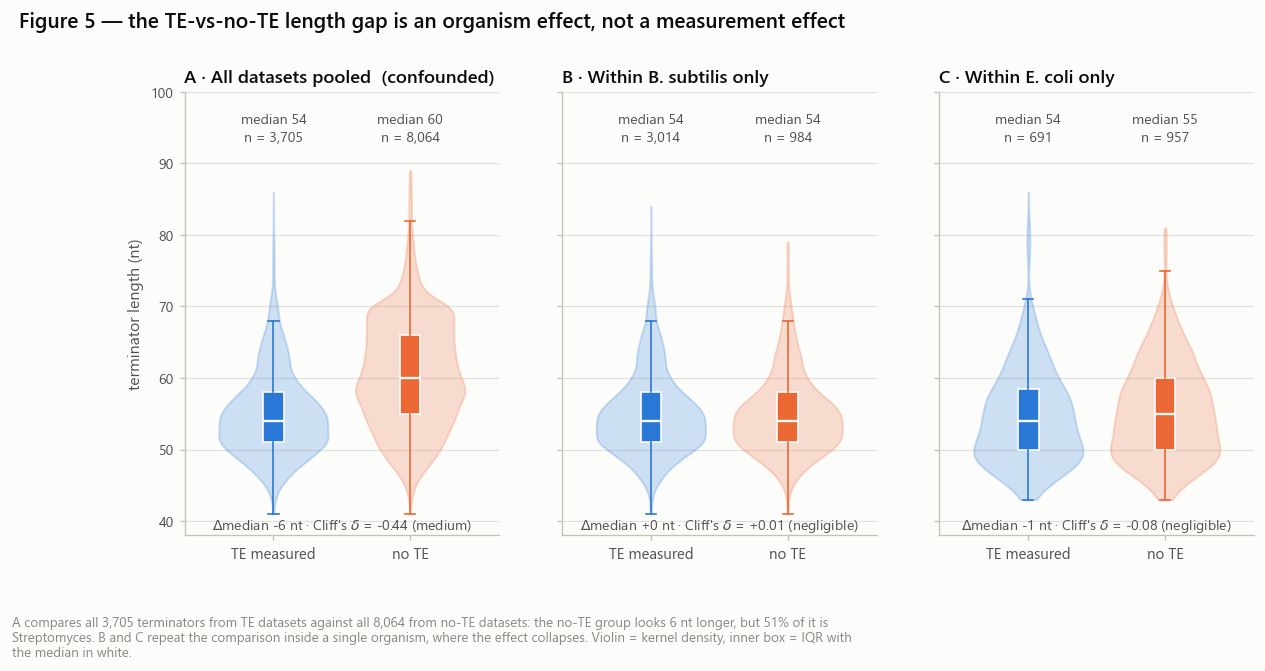

In [24]:
# ---- Figure 5: TE split, pooled and then matched within organism ------
def violin_pair(ax, groups, colors, labels, ylab=True, lo=38, hi=100):
    for i, (v, c) in enumerate(zip(groups, colors)):
        v = np.asarray(v, float)
        parts = ax.violinplot([v], positions=[i], widths=0.8, showextrema=False)
        for body in parts["bodies"]:
            body.set_facecolor(c); body.set_alpha(0.22)
            body.set_edgecolor(c); body.set_linewidth(1.2)
        bp = ax.boxplot([v], positions=[i], widths=0.15, patch_artist=True, showfliers=False,
                        medianprops=dict(color=SURFACE, lw=1.4),
                        whiskerprops=dict(color=c, lw=1.0),
                        capprops=dict(color=c, lw=1.0), zorder=4)
        bp["boxes"][0].set_facecolor(c); bp["boxes"][0].set_edgecolor(SURFACE)
        ax.text(i, hi - 3, "median {:.0f}\nn = {:,}".format(np.median(v), len(v)),
                ha="center", va="top", fontsize=8.5, color=INK2, linespacing=1.5)
    ax.set_xticks(range(len(groups)))
    ax.set_xticklabels(labels, fontsize=9)
    ax.set_xlim(-0.65, len(groups) - 0.35)
    ax.set_ylim(lo, hi)
    if ylab:
        ax.set_ylabel("terminator length (nt)")
    style_axes(ax, grid="y")


fig, axes = plt.subplots(1, 3, figsize=(11.5, 4.8), sharey=True)

panels = [(axes[0], None, "A · All datasets pooled  (confounded)", te_tests.iloc[0]),
          (axes[1], "Bacillus subtilis", "B · Within B. subtilis only", te_tests.iloc[1]),
          (axes[2], "Escherichia coli", "C · Within E. coli only", te_tests.iloc[2])]

for ax, sp, title, row in panels:
    s = df if sp is None else df[df["species"] == sp]
    violin_pair(ax,
                [s.loc[s["te_group"] == TE_MEASURED, LEN].dropna().to_numpy(float),
                 s.loc[s["te_group"] == TE_NONE, LEN].dropna().to_numpy(float)],
                [TE_COLOR[TE_MEASURED], TE_COLOR[TE_NONE]],
                ["TE measured", "no TE"], ylab=(sp is None))
    ax.set_title(title)
    ax.text(0.5, 0.015, "$\\Delta$median {:+.0f} nt · Cliff's $\\delta$ = {:+.2f} ({})".format(
        row["median_diff"], row["cliffs_delta"], row["effect"]),
        transform=ax.transAxes, ha="center", fontsize=8.5, color=INK2)

fig.suptitle("Figure 5 — the TE-vs-no-TE length gap is an organism effect, not a measurement effect",
             x=0.005, ha="left", fontsize=12.5, fontweight="semibold", y=1.02)
fig_note(fig, ("A compares all {:,} terminators from TE datasets against all {:,} from no-TE datasets: "
               "the no-TE group looks {:.0f} nt longer, but {:.0f}% of it is Streptomyces. B and C repeat the "
               "comparison inside a single organism, where the effect collapses. Violin = kernel density, "
               "inner box = IQR with the median in white.").format(
              len(a), len(b), -te_tests.iloc[0]["median_diff"], strep_share), y=-0.03)
save(fig, "fig05_te_group_comparison")
plt.show()

saved: outputs\terminator_length\figures\fig06_atlas_coverage_and_confound.png


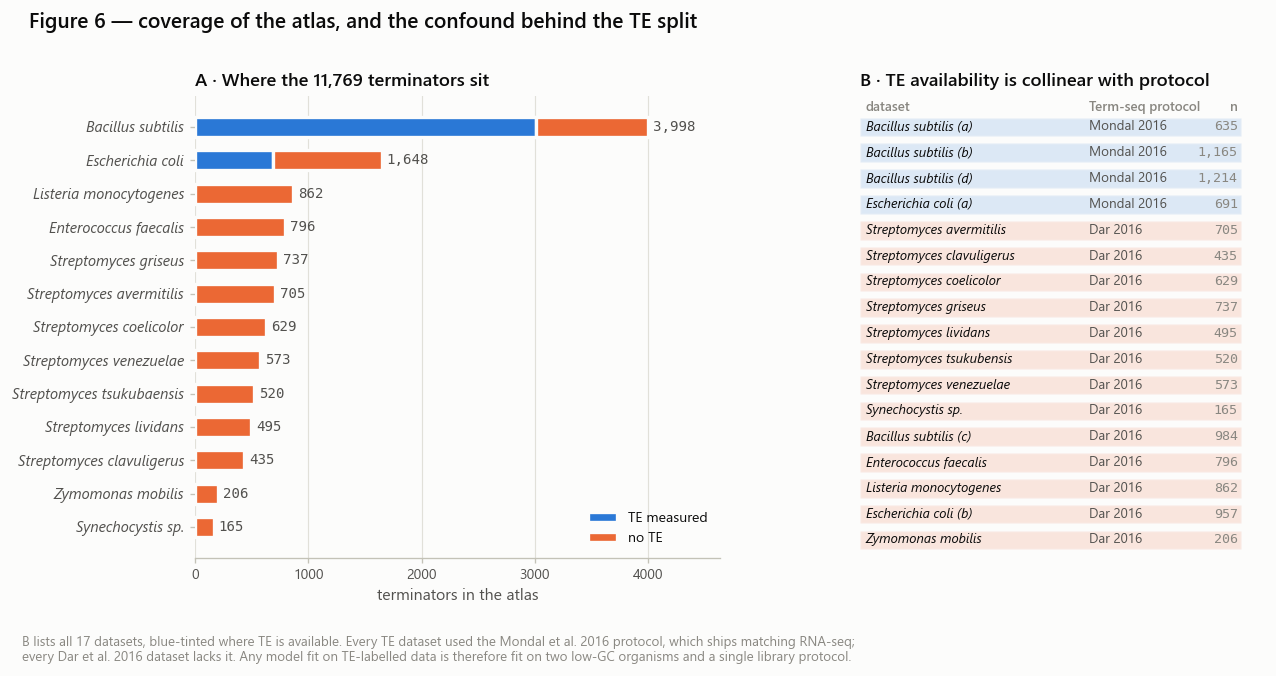

In [25]:
# ---- Figure 6: how the atlas is actually distributed ------------------
cnt = (df.pivot_table(index="species", columns="te_group", values=LEN,
                      aggfunc="size", fill_value=0)
         .reindex(columns=[TE_MEASURED, TE_NONE], fill_value=0))
cnt = cnt.loc[cnt.sum(axis=1).sort_values().index]

fig = plt.figure(figsize=(11.5, 5.0))
gs = fig.add_gridspec(1, 2, width_ratios=[1.3, 1], wspace=0.30)

ax = fig.add_subplot(gs[0, 0])
ypos = np.arange(len(cnt))
left = np.zeros(len(cnt))
for grp in [TE_MEASURED, TE_NONE]:
    w = cnt[grp].to_numpy(float)
    ax.barh(ypos, w, left=left, height=0.6, color=TE_COLOR[grp],
            edgecolor=SURFACE, linewidth=2.0, zorder=3, label=grp)
    left += w
for i, tot in enumerate(cnt.sum(axis=1)):
    ax.text(tot + 45, i, "{:,}".format(int(tot)), va="center", fontsize=8.5,
            color=INK2, family="monospace")
ax.set_yticks(ypos)
ax.set_yticklabels(cnt.index, fontsize=9, fontstyle="italic")
ax.set_xlim(0, cnt.sum(axis=1).max() * 1.16)
ax.set_xlabel("terminators in the atlas")
ax.set_title("A · Where the 11,769 terminators sit")
ax.legend(loc="lower right")
style_axes(ax, grid="x", hide=("top", "right", "left"))

ax = fig.add_subplot(gs[0, 1])
conf = (df.groupby("dataset")[["te_group", "protocol", "lineage"]].first()
          .assign(n=df.groupby("dataset").size())
          .sort_values(["te_group", "lineage"], ascending=[True, True]))
for i, (name, r) in enumerate(conf.iterrows()):
    y = len(conf) - 1 - i
    ax.barh([y], [1], height=0.72, color=TE_COLOR[r["te_group"]], alpha=0.15,
            edgecolor=SURFACE, linewidth=1.6, zorder=2)
    ax.text(0.015, y, name, fontsize=8, color=INK, va="center", style="italic")
    ax.text(0.60, y, r["protocol"].replace(" et al. ", " "), fontsize=8, color=INK2, va="center")
    ax.text(0.99, y, "{:,}".format(int(r["n"])), fontsize=8, color=MUTED, va="center",
            ha="right", family="monospace")
for x, lab, ha in [(0.015, "dataset", "left"), (0.60, "Term-seq protocol", "left"), (0.99, "n", "right")]:
    ax.text(x, len(conf) - 0.25, lab, fontsize=8, color=MUTED, va="center",
            ha=ha, fontweight="semibold")
ax.set_xlim(0, 1.06); ax.set_ylim(-0.7, len(conf) + 0.2)
ax.set_xticks([]); ax.set_yticks([])
for s in ax.spines.values():
    s.set_visible(False)
ax.set_title("B · TE availability is collinear with protocol")

fig.suptitle("Figure 6 — coverage of the atlas, and the confound behind the TE split",
             x=0.005, ha="left", fontsize=12.5, fontweight="semibold", y=1.02)
fig_note(fig, "B lists all 17 datasets, blue-tinted where TE is available. Every TE dataset used the "
              "Mondal et al. 2016 protocol, which ships matching RNA-seq; every Dar et al. 2016 dataset "
              "lacks it. Any model fit on TE-labelled data is therefore fit on two low-GC organisms and "
              "a single library protocol.", y=-0.02)
save(fig, "fig06_atlas_coverage_and_confound")
plt.show()

In [26]:
cnt.assign(total=cnt.sum(axis=1)).sort_values("total", ascending=False)

te_group,TE measured,no TE,total
species,,,
Bacillus subtilis,3014,984,3998
Escherichia coli,691,957,1648
Listeria monocytogenes,0,862,862
Enterococcus faecalis,0,796,796
Streptomyces griseus,0,737,737
Streptomyces avermitilis,0,705,705
Streptomyces coelicolor,0,629,629
Streptomyces venezuelae,0,573,573
Streptomyces tsukubaensis,0,520,520


## 8. Does terminator length predict termination efficiency?

Only answerable in the four datasets that have TE. This is the part directly relevant to
the model: how much signal a length feature alone carries, and how consistent that signal
is between studies.

saved: outputs\terminator_length\figures\fig07_length_vs_te.png


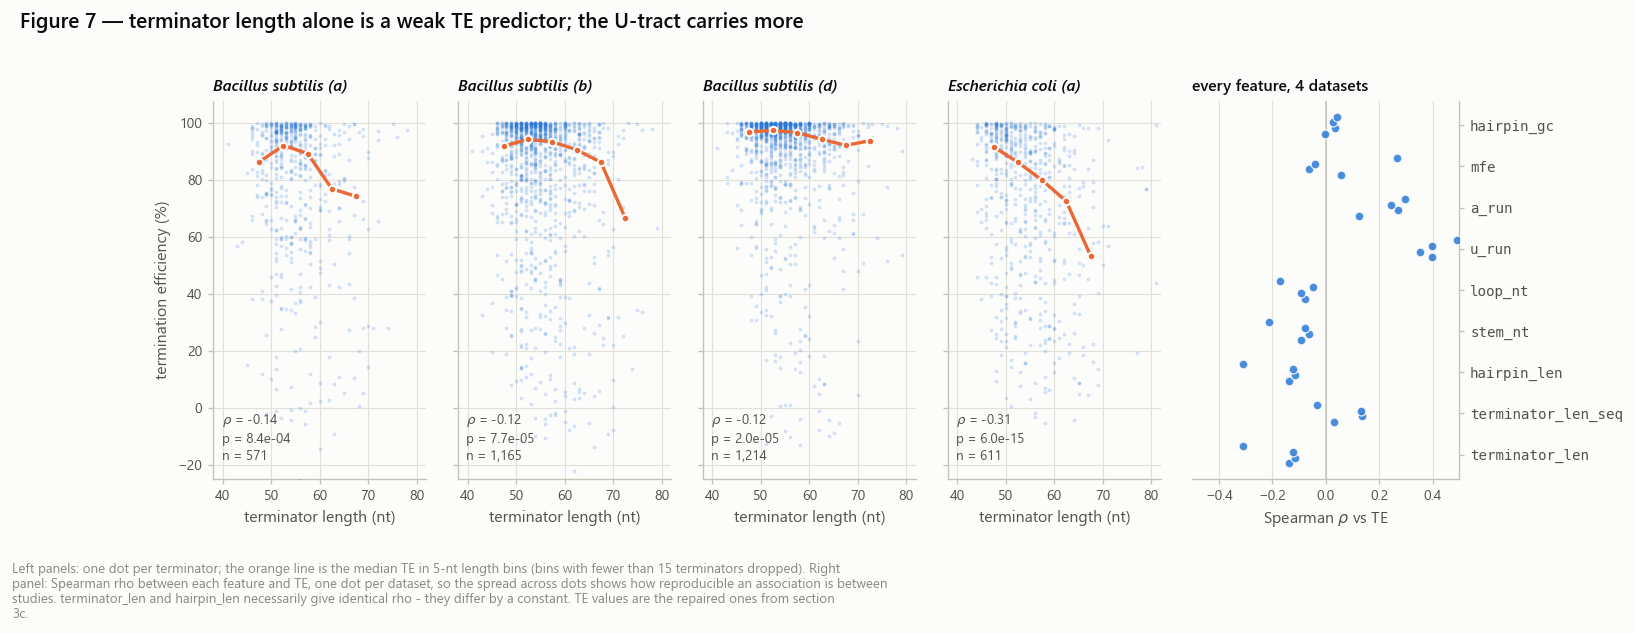

In [27]:
te_df = df[df["te_pct"].notna()].copy()
te_sets = sorted(te_df["dataset"].unique())
feat = ["terminator_len", "terminator_len_seq", "hairpin_len", "stem_nt",
        "loop_nt", "u_run", "a_run", "mfe", "hairpin_gc"]

fig = plt.figure(figsize=(13.4, 4.1))
gs = fig.add_gridspec(1, len(te_sets) + 1, width_ratios=[1] * len(te_sets) + [1.25], wspace=0.14)

scat_axes = []
for j, name in enumerate(te_sets):
    ax = fig.add_subplot(gs[0, j], sharey=scat_axes[0] if scat_axes else None)
    scat_axes.append(ax)
    s = te_df[te_df["dataset"] == name]
    x = s[LEN].to_numpy(float); y = s["te_pct"].to_numpy(float)
    ok = np.isfinite(x) & np.isfinite(y)
    x, y = x[ok], y[ok]
    ax.scatter(x, y, s=5, color=SER["blue"], alpha=0.20, linewidths=0, zorder=3)
    edges = np.arange(40, 85, 5)
    idx = np.digitize(x, edges)
    bx, by = [], []
    for k in range(1, len(edges)):
        m = idx == k
        if m.sum() >= 15:
            bx.append((edges[k - 1] + edges[k]) / 2); by.append(np.median(y[m]))
    ax.plot(bx, by, color=SER["orange"], lw=2, marker="o", ms=4.5,
            markeredgecolor=SURFACE, markeredgewidth=1.2, zorder=5)
    rho, pv = stats.spearmanr(x, y)
    ax.set_title(name, fontsize=9.5, fontstyle="italic")
    ax.text(0.04, 0.05, "$\\rho$ = {:+.2f}\np = {:.1e}\nn = {:,}".format(rho, pv, len(x)),
            transform=ax.transAxes, fontsize=8, color=INK2, linespacing=1.4)
    ax.set_xlabel("terminator length (nt)")
    ax.set_xlim(38, 82)
    style_axes(ax, grid="both")
    if j:
        ax.tick_params(labelleft=False)
scat_axes[0].set_ylabel("termination efficiency (%)")
scat_axes[0].set_ylim(-25, 108)

ax = fig.add_subplot(gs[0, len(te_sets)])
rhos = pd.DataFrame({d: [stats.spearmanr(g[f], g["te_pct"], nan_policy="omit").statistic for f in feat]
                     for d, g in te_df.groupby("dataset")}, index=feat)
ax.axvline(0, color=AXIS, lw=0.9, zorder=2)
for j, d in enumerate(rhos.columns):
    ax.scatter(rhos[d], np.arange(len(feat)) + (j - 1.5) * 0.14, s=28,
               color=SER["blue"], alpha=0.85, edgecolor=SURFACE, linewidth=0.8, zorder=4)
ax.set_yticks(np.arange(len(feat)))
ax.set_yticklabels(feat, fontsize=8.5, family="monospace")
ax.yaxis.tick_right()               # keep the labels clear of the scatter panels
ax.set_xlabel("Spearman $\\rho$ vs TE")
ax.set_title("every feature, 4 datasets", fontsize=9.5)
ax.set_xlim(-0.5, 0.5)
ax.set_ylim(-0.6, len(feat) - 0.4)
style_axes(ax, grid="x", hide=("top", "left"))

fig.suptitle("Figure 7 — terminator length alone is a weak TE predictor; the U-tract carries more",
             x=0.005, ha="left", fontsize=12.5, fontweight="semibold", y=1.06)
fig_note(fig, "Left panels: one dot per terminator; the orange line is the median TE in 5-nt length bins "
              "(bins with fewer than 15 terminators dropped). Right panel: Spearman rho between each "
              "feature and TE, one dot per dataset, so the spread across dots shows how reproducible an "
              "association is between studies. terminator_len and hairpin_len necessarily give identical "
              "rho - they differ by a constant. TE values are the repaired ones from section 3c.", y=-0.06)
save(fig, "fig07_length_vs_te")
plt.show()

In [28]:
rhos.round(3).rename_axis("feature").to_csv(TAB / "spearman_feature_vs_te.csv")
rhos.round(3)

,Bacillus subtilis (a),Bacillus subtilis (b),Bacillus subtilis (d),Escherichia coli (a)
terminator_len,-0.139,-0.116,-0.122,-0.309
terminator_len_seq,0.032,0.135,0.133,-0.034
hairpin_len,-0.139,-0.116,-0.122,-0.309
stem_nt,-0.092,-0.063,-0.077,-0.215
loop_nt,-0.079,-0.092,-0.049,-0.172
u_run,0.397,0.353,0.400,0.491
a_run,0.125,0.272,0.246,0.296
mfe,0.056,-0.062,-0.039,0.266
hairpin_gc,-0.003,0.035,0.028,0.041


## 9. How much upstream context does the model need?

The model input window is **80 nt upstream + 19 nt downstream** of the 3′ end. This section
is the evidence for the upstream half of that choice (the downstream half is set by other
considerations). The question it answers: how far upstream of the 3′ end does the
terminator actually reach?

**Source 1 — the TERMITe atlas (this notebook, 11,769 terminators, 13 organisms).**

```
upstream extent  =  A-tract (15) + hairpin + gap between hairpin end and POT
```

**Source 2 — an independent dataset that is not in the atlas.** Chen *et al.* 2013
(`D02`) measured 582 natural and synthetic terminators in *E. coli* with a dual-fluorescence
reporter library — a different organism set, a different assay, and a different annotation
convention (A-tract 8 nt, U-tract 12 nt against TERMITe's 15/15). Their per-terminator
decomposition is in `Chen_2013_terminators/terminator_lengths.csv`; see the `SOURCE.md`
beside it for provenance. Because their terminator ends at the 3′ end of the U-tract while
termination happens *inside* it, their `terminator_len` is an **upper bound** on the
upstream context those terminators need — the conservative direction for sizing a window.

The two sources are not commensurable in the middle of the distribution (different tract
conventions move the median), but they are directly comparable where it matters for a
window: the far right tail.

In [29]:
# ---- source 1: TERMITe atlas ------------------------------------------
df["upstream_extent"] = (df["tt_a_window"].fillna(df["rf_a_window"])
                         + df["hairpin_len"] + df["pot_to_hairpin"])
ue = df["upstream_extent"].dropna().to_numpy(float)

# ---- source 2: Chen et al. 2013 (582 terminators, not in the atlas) ----
CHEN = PROJECT / "Chen_2013_terminators" / "terminator_lengths.csv"
chen = pd.read_csv(CHEN)
cl = chen["terminator_len"].to_numpy(float)
print("TERMITe atlas  n={:,}  median {:.0f}  p99 {:.0f}  max {:.0f} nt".format(
    len(ue), np.median(ue), np.percentile(ue, 99), ue.max()))
print("Chen 2013      n={:,}  median {:.0f}  p99 {:.0f}  max {:.0f} nt".format(
    len(cl), np.median(cl), np.percentile(cl, 99), cl.max()))

TERMITe atlas  n=11,769  median 48  p99 67  max 80 nt
Chen 2013      n=582  median 40  p99 65  max 77 nt


saved: outputs\terminator_length\figures\fig08_input_window.png


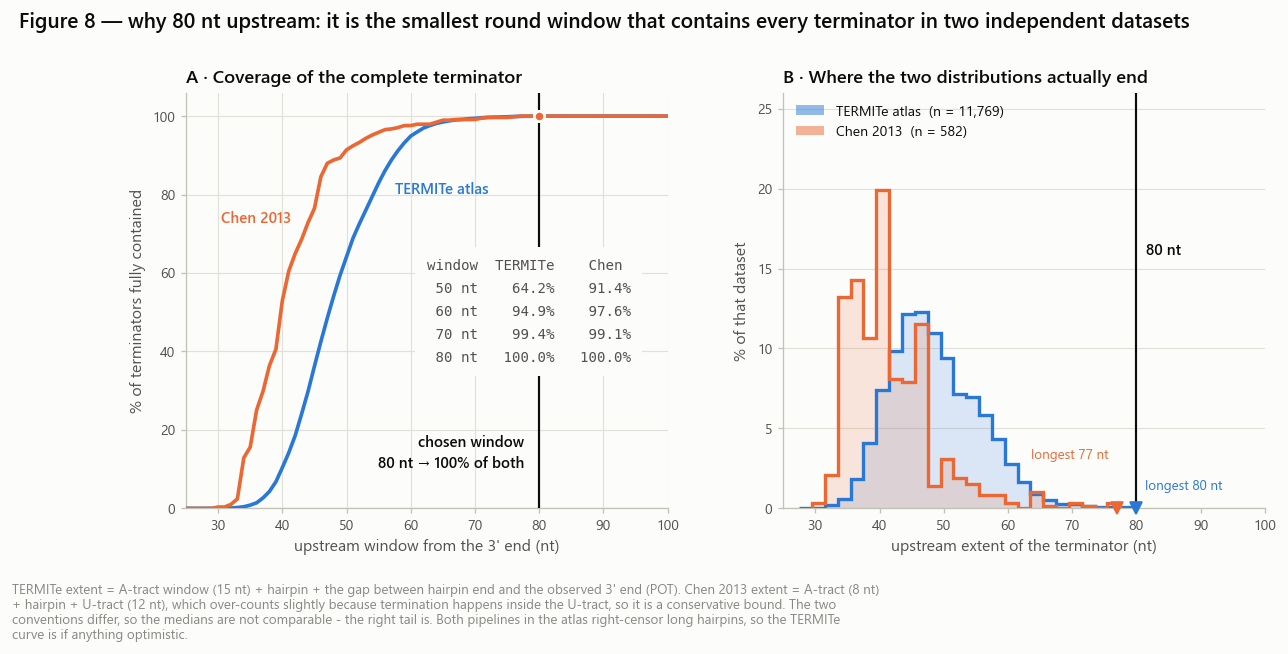

In [30]:
WINDOW = 80                       # the chosen upstream window
SOURCES = [("TERMITe atlas (11,769 terminators, 13 organisms)", ue, SER["blue"]),
           ("Chen 2013 (582 terminators, E. coli reporter library)", cl, SER["orange"])]

windows = np.arange(25, 101)

fig, axes = plt.subplots(1, 2, figsize=(11.6, 4.5), gridspec_kw={"wspace": 0.24})

# --- A: coverage curves -------------------------------------------------
ax = axes[0]
for label, v, c in SOURCES:
    ax.plot(windows, [(v <= w).mean() * 100 for w in windows], color=c, lw=2.2, zorder=4)
    ax.scatter([WINDOW], [(v <= WINDOW).mean() * 100], s=38, color=c,
               edgecolor=SURFACE, linewidth=1.6, zorder=6)
ax.annotate("TERMITe atlas", xy=(56, (ue <= 56).mean() * 100), xytext=(6, -14),
            textcoords="offset points", color=SER["blue"], fontsize=9, fontweight="semibold")
ax.annotate("Chen 2013", xy=(43, (cl <= 43).mean() * 100), xytext=(-6, 10),
            textcoords="offset points", ha="right", color=SER["orange"],
            fontsize=9, fontweight="semibold")
ax.axvline(WINDOW, color=INK, lw=1.3, zorder=5)
ax.annotate("chosen window\n{} nt → 100% of both".format(WINDOW),
            xy=(WINDOW, 14), xytext=(-9, 0), textcoords="offset points",
            ha="right", va="center", fontsize=9, color=INK, fontweight="semibold",
            linespacing=1.4)
ax.text(0.50, 0.60, "window  TERMITe    Chen\n" + "\n".join(
    "{:>3} nt   {:>5.1f}%   {:>5.1f}%".format(w, (ue <= w).mean() * 100, (cl <= w).mean() * 100)
    for w in [50, 60, 70, 80]),
    transform=ax.transAxes, fontsize=8.5, color=INK2, linespacing=1.8,
    va="top", family="monospace", zorder=7,
    bbox=dict(facecolor=SURFACE, edgecolor="none", pad=7))
ax.set_xlim(25, 100); ax.set_ylim(0, 106)
ax.set_xlabel("upstream window from the 3' end (nt)")
ax.set_ylabel("% of terminators fully contained")
ax.set_title("A · Coverage of the complete terminator")
style_axes(ax, grid="both")

# --- B: the two length distributions ------------------------------------
ax = axes[1]
tips = [("Chen 2013", cl, SER["orange"], -5, 30, "right"),
        ("TERMITe atlas", ue, SER["blue"], 5, 11, "left")]
for label, v, c in SOURCES:
    bins = np.arange(v.min() - 0.5, v.max() + 1.5, 2)
    ax.hist(v, bins=bins, weights=np.full(v.size, 100 / v.size), color=c, alpha=0.16, zorder=2)
    ax.hist(v, bins=bins, weights=np.full(v.size, 100 / v.size), histtype="step",
            color=c, lw=2, zorder=3)
for _, v, c, dx, dy, ha in tips:
    ax.plot([v.max()], [0], marker="v", ms=7, color=c, clip_on=False, zorder=6)
    ax.annotate("longest {:.0f} nt".format(v.max()), xy=(v.max(), 0), xytext=(dx, dy),
                textcoords="offset points", ha=ha, fontsize=8, color=c)
ax.axvline(WINDOW, color=INK, lw=1.3, zorder=5)
ax.annotate("{} nt".format(WINDOW), xy=(WINDOW, 0.62), xycoords=("data", "axes fraction"),
            xytext=(6, 0), textcoords="offset points", ha="left", va="center",
            fontsize=9, color=INK, fontweight="semibold")
ax.set_xlim(25, 100)
ax.set_ylim(0, 26)
ax.set_xlabel("upstream extent of the terminator (nt)")
ax.set_ylabel("% of that dataset")
ax.set_title("B · Where the two distributions actually end")
ax.legend(handles=[Patch(facecolor=SER["blue"], alpha=0.5, label="TERMITe atlas  (n = 11,769)"),
                   Patch(facecolor=SER["orange"], alpha=0.5, label="Chen 2013  (n = 582)")],
          loc="upper left", bbox_to_anchor=(0.0, 1.0), fontsize=8.5)
style_axes(ax, grid="y")

fig.suptitle("Figure 8 — why 80 nt upstream: it is the smallest round window that contains "
             "every terminator in two independent datasets",
             x=0.005, ha="left", fontsize=12.5, fontweight="semibold", y=1.03)
fig_note(fig, "TERMITe extent = A-tract window (15 nt) + hairpin + the gap between hairpin end and the "
              "observed 3' end (POT). Chen 2013 extent = A-tract (8 nt) + hairpin + U-tract (12 nt), "
              "which over-counts slightly because termination happens inside the U-tract, so it is a "
              "conservative bound. The two conventions differ, so the medians are not comparable - the "
              "right tail is. Both pipelines in the atlas right-censor long hairpins, so the TERMITe "
              "curve is if anything optimistic.", y=-0.03)
save(fig, "fig08_input_window")
plt.show()

In [ ]:
# ---- Figure 8, clean copy: white, no titles, no caption, no 80 nt marker ----
# Same data and drawing as Figure 8 above (reuses SOURCES and windows from that
# cell), for slides and papers. Panel letters replace the titles.
PLAIN_BG, PLAIN_GRID, PLAIN_AXIS = "#ffffff", "#e5e5e5", "#c4c4c4"

def plain_axes(ax, grid):
    # style_axes, then swap the warm chrome for plain white + neutral grays
    style_axes(ax, grid=grid)
    ax.set_facecolor(PLAIN_BG)
    for s in ax.spines.values():
        s.set_color(PLAIN_AXIS)
    ax.tick_params(color=PLAIN_AXIS)
    ax.grid(True, axis=grid, color=PLAIN_GRID, lw=0.7, ls="-", zorder=0)

fig, axes = plt.subplots(1, 2, figsize=(11.6, 4.5), gridspec_kw={"wspace": 0.24},
                         facecolor=PLAIN_BG)

# --- A: coverage curves -------------------------------------------------
ax = axes[0]
for label, v, c in SOURCES:
    ax.plot(windows, [(v <= w).mean() * 100 for w in windows], color=c, lw=2.2, zorder=4)
ax.annotate("TERMITe atlas", xy=(56, (ue <= 56).mean() * 100), xytext=(6, -14),
            textcoords="offset points", color=SER["blue"], fontsize=9, fontweight="semibold")
ax.annotate("Chen 2013", xy=(43, (cl <= 43).mean() * 100), xytext=(-6, 10),
            textcoords="offset points", ha="right", color=SER["orange"],
            fontsize=9, fontweight="semibold")
ax.text(0.50, 0.60, "window  TERMITe    Chen\n" + "\n".join(
    "{:>3} nt   {:>5.1f}%   {:>5.1f}%".format(w, (ue <= w).mean() * 100, (cl <= w).mean() * 100)
    for w in [50, 60, 70, 80]),
    transform=ax.transAxes, fontsize=8.5, color=INK2, linespacing=1.8,
    va="top", family="monospace", zorder=7,
    bbox=dict(facecolor=PLAIN_BG, edgecolor="none", pad=7))
ax.set_xlim(25, 100); ax.set_ylim(0, 106)
ax.set_xlabel("upstream window from the 3' end (nt)")
ax.set_ylabel("% of terminators fully contained")
plain_axes(ax, grid="both")

# --- B: the two length distributions ------------------------------------
ax = axes[1]
tips = [("Chen 2013", cl, SER["orange"], -5, 30, "right"),
        ("TERMITe atlas", ue, SER["blue"], 5, 11, "left")]
for label, v, c in SOURCES:
    bins = np.arange(v.min() - 0.5, v.max() + 1.5, 2)
    ax.hist(v, bins=bins, weights=np.full(v.size, 100 / v.size), color=c, alpha=0.16, zorder=2)
    ax.hist(v, bins=bins, weights=np.full(v.size, 100 / v.size), histtype="step",
            color=c, lw=2, zorder=3)
for _, v, c, dx, dy, ha in tips:
    ax.plot([v.max()], [0], marker="v", ms=7, color=c, clip_on=False, zorder=6)
    ax.annotate("longest {:.0f} nt".format(v.max()), xy=(v.max(), 0), xytext=(dx, dy),
                textcoords="offset points", ha=ha, fontsize=8, color=c)
ax.set_xlim(25, 100)
ax.set_ylim(0, 26)
ax.set_xlabel("upstream extent of the terminator (nt)")
ax.set_ylabel("% of that dataset")
ax.legend(handles=[Patch(facecolor=SER["blue"], alpha=0.5, label="TERMITe atlas  (n = 11,769)"),
                   Patch(facecolor=SER["orange"], alpha=0.5, label="Chen 2013  (n = 582)")],
          loc="upper left", bbox_to_anchor=(0.0, 1.0), fontsize=8.5)
plain_axes(ax, grid="y")

for ax, letter in zip(axes, "AB"):
    ax.annotate(letter, xy=(0, 1), xycoords="axes fraction", xytext=(-36, 12),
                textcoords="offset points", ha="left", va="bottom",
                fontsize=14, fontweight="bold", color=INK)
with mpl.rc_context({"savefig.facecolor": PLAIN_BG}):
    save(fig, "fig08_input_window_clean")
plt.show()

saved: outputs\terminator_length\figures\fig08b_window_by_organism.png


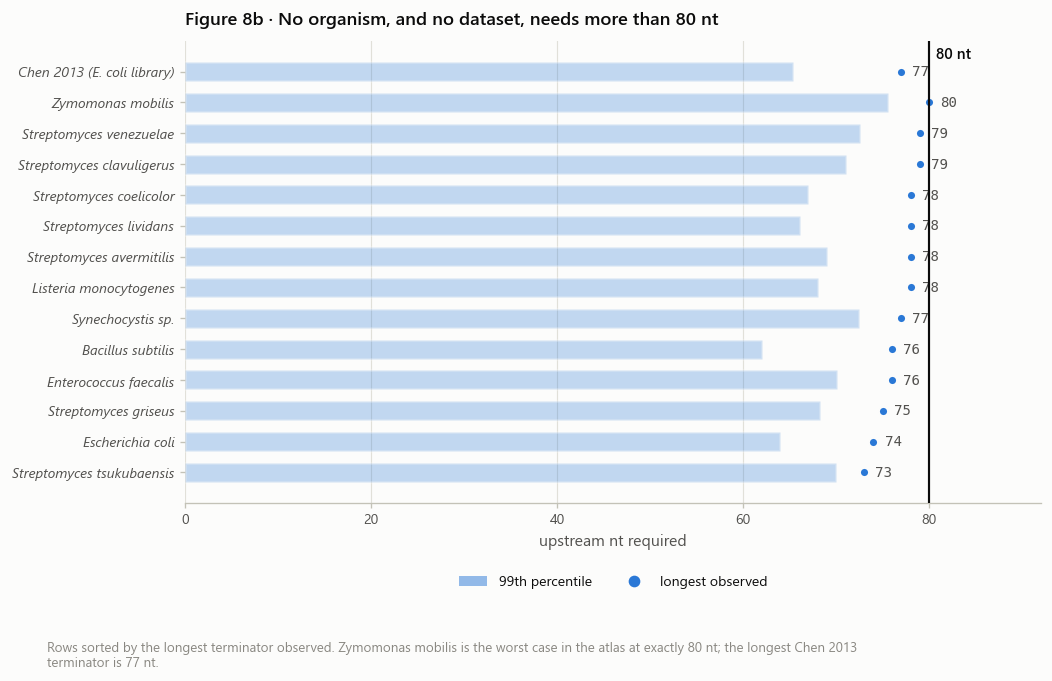

In [31]:
# ---- Figure 8b: the requirement, organism by organism -----------------
req = (df.groupby("species")["upstream_extent"]
         .agg(n="size", p95=lambda s: s.quantile(.95), p99=lambda s: s.quantile(.99), max="max")
         .sort_values("max"))
req.loc["Chen 2013 (E. coli library)"] = [len(cl), np.percentile(cl, 95), np.percentile(cl, 99), cl.max()]

fig, ax = plt.subplots(figsize=(9.2, 5.0))
y = np.arange(len(req))
ax.barh(y, req["p99"].to_numpy(), height=0.62, color=SER["blue"], alpha=0.28,
        edgecolor=SURFACE, linewidth=1.6, zorder=3)
ax.scatter(req["max"].to_numpy(), y, s=30, color=SER["blue"], zorder=5,
           edgecolor=SURFACE, linewidth=1.2)
for i, (p99, mx) in enumerate(zip(req["p99"], req["max"])):
    ax.text(mx + 1.2, i, "{:.0f}".format(mx), va="center", fontsize=8.5,
            color=INK2, family="monospace")
ax.axvline(WINDOW, color=INK, lw=1.3, zorder=6)
ax.annotate("80 nt", xy=(WINDOW, 1.0), xycoords=("data", "axes fraction"),
            xytext=(4, -3), textcoords="offset points", va="top",
            fontsize=9, color=INK, fontweight="semibold")
ax.set_yticks(y)
ax.set_yticklabels(req.index, fontsize=8.5, fontstyle="italic")
ax.set_xlim(0, 92)
ax.set_xlabel("upstream nt required")
ax.set_title("Figure 8b · No organism, and no dataset, needs more than 80 nt", pad=10)
ax.legend(handles=[Patch(facecolor=SER["blue"], alpha=0.5, label="99th percentile"),
                   Line2D([], [], marker="o", ls="none", color=SER["blue"], ms=6, label="longest observed")],
          loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2, fontsize=8.5)
style_axes(ax, grid="x", hide=("top", "right", "left"))
fig_note(fig, "Rows sorted by the longest terminator observed. Zymomonas mobilis is the worst case in "
              "the atlas at exactly 80 nt; the longest Chen 2013 terminator is 77 nt.", y=-0.12)
save(fig, "fig08b_window_by_organism")
plt.show()

In [32]:
win_tbl = pd.DataFrame({
    "upstream window (nt)": [50, 60, 65, 70, 75, 80],
    "% TERMITe covered": [round((ue <= w).mean() * 100, 1) for w in [50, 60, 65, 70, 75, 80]],
    "% Chen 2013 covered": [round((cl <= w).mean() * 100, 1) for w in [50, 60, 65, 70, 75, 80]],
})
win_tbl.to_csv(TAB / "input_window_coverage.csv", index=False)
req.round(1).to_csv(TAB / "upstream_requirement_by_organism.csv")
print("TERMITe upstream extent: median {:.0f}, p95 {:.0f}, p99 {:.0f}, max {:.0f} nt".format(
    np.median(ue), np.percentile(ue, 95), np.percentile(ue, 99), ue.max()))
print("Chen 2013 length       : median {:.0f}, p95 {:.0f}, p99 {:.0f}, max {:.0f} nt\n".format(
    np.median(cl), np.percentile(cl, 95), np.percentile(cl, 99), cl.max()))
win_tbl

TERMITe upstream extent: median 48, p95 61, p99 67, max 80 nt
Chen 2013 length       : median 40, p95 54, p99 65, max 77 nt



,upstream window (nt),% TERMITe covered,% Chen 2013 covered
0,50,64.2,91.4
1,60,94.9,97.6
2,65,98.5,99.0
3,70,99.4,99.1
4,75,99.8,99.7
5,80,100.0,100.0


## 10. What this means for the TE model

**Terminator length — A-tract + hairpin + U-tract, per protocol**

| | n | median | IQR | 90 % range | full range |
|---|---|---|---|---|---|
| TransTermHP protocol | 8,212 | **56 nt** | 52–63 | 48–73 | 41–89 |
| RNAfold protocol | 10,720 | **58 nt** | 53–64 | 48–70 | 42–70 |
| combined (primary) | 11,769 | **58 nt** | 53–64 | 48–71 | 41–89 |
| combined, tracts measured from sequence | 11,769 | 34 nt | 30–39 | 24–46 | 14–69 |

* The two protocols agree exactly on **84 %** of the 7,163 terminators they both call, and
  to within 2 nt on 86 % (Spearman ρ = 0.89). Where they differ, TransTermHP is the longer
  call — its stem-loop limit is 59 nt against the RNAfold scan's 40 nt.
* Because both protocols report the A- and U-tract as **fixed 15-nt windows**, terminator
  length is exactly `hairpin + 30`. Every ranking, every group difference and every
  correlation below is therefore identical to the hairpin's; only the absolute numbers move.
* Inside that 30 nt the real tracts are much shorter: measured from the sequence, the
  **U-tract run** is median 5 nt (TransTermHP) / 3 nt (RNAfold) and the **A-tract run**
  median 2 / 1 nt, so the measured footprint is a median of 34 nt rather than 58.
* Both protocols **right-censor** long terminators (ceilings of 89 nt and 70 nt). Real
  terminators in high-GC organisms are longer than the atlas reports.

**Input window — the evidence for 80 nt upstream.** Measuring back from the 3′ end to the
5′ end of the terminator:

| upstream window | TERMITe atlas | Chen 2013 |
|---|---|---|
| 50 nt | 64.2 % | 91.4 % |
| 60 nt | 94.9 % | 97.6 % |
| 70 nt | 99.4 % | 99.1 % |
| **80 nt** | **100 %** | **100 %** |

The longest terminator in the atlas reaches exactly 80 nt (*Z. mobilis*) and the longest in
Chen 2013 reaches 77 nt, so **80 nt is the smallest round window that loses nothing in
either dataset** — and the two datasets share no organisms beyond *E. coli*, no assay and
no annotation convention, so the agreement is not circular. 70 nt would still truncate
~1 in 150 terminators, and those are the long-stem *Streptomyces* and *Z. mobilis* cases
that a length- or structure-sensitive model can least afford to see cut off. Both atlas
pipelines right-censor long hairpins, so if anything 80 nt is the floor rather than the
ceiling. The atlas already stores 100 nt upstream + 10 nt downstream in its `sequence`
column, so the upstream side needs no re-extraction — just take a wider slice.

**Species structure**

* Length splits into two regimes set by GC content rather than by phylogeny as such:
  *Streptomyces* (GC ≈ 70 %) at medians of 62–65 nt, everything else at 54–58 nt, with
  *E. faecalis* (median 63 nt) the one low-GC exception. Across the 13 organisms the rank
  correlation between context GC and median length is ρ = 0.67.
* Because of that, **pooling species for pre-training is reasonable; pooling for
  fine-tuning is not** — a length or MFE feature means something different in a 70 %-GC
  genome. This supports the README's decision to fine-tune within a single organism.

**The TE split**

* Only **4 of 17 datasets (3,705 of 11,769 terminators, 31 %)** sit in TE-measured
  datasets, and 3,561 of those actually carry a TE value. They are *B. subtilis* ×3 and
  *E. coli* ×1, all Mondal *et al.* 2016 protocol. TE availability, library protocol and
  organism are perfectly collinear.
* The apparent "TE datasets have shorter terminators" effect (Δmedian −6 nt, Cliff's
  δ = −0.44) is an artefact of that collinearity — within *B. subtilis* it vanishes
  (δ = +0.01) and within *E. coli* it is negligible (δ = −0.08). See Figure 5B, C.
* Where TE does exist, **length is a weak predictor of it** (Spearman ρ −0.12 to −0.31)
  while the **U-tract run is the strongest and most reproducible single feature**
  (ρ +0.35 to +0.49 across all four datasets). If the model gets one hand-crafted feature,
  make it the U-tract run, not the terminator length.
* Practical consequence: the labelled portion of this atlas is effectively **two low-GC
  organisms under one protocol**. Treat a TE model trained on it as organism-specific
  until tested on held-out species, and use the 8,064 unlabelled terminators for
  **pre-training** — which is exactly how `datasets_v2.csv` classifies `D08`.

**Data-quality items to carry forward**

1. 183 TE values in Supplementary Table 2 are Excel date serials; repair them as in §3c
   before use. The published file is wrong as distributed.
2. 53 TE values are negative (a TERMITe artefact). Decide explicitly whether to clip to 0
   or drop.
3. Three `transtermhp hairpin` cells begin with `=` and come back as `NaN` from
   `pd.read_excel`; the loader here reads raw cell values instead.
4. Length is right-censored by both protocols — do not fit an unbounded model to the right
   tail without acknowledging it.

In [33]:
# ---- write the tidy feature table -------------------------------------
keep = ["dataset", "species", "lineage", "te_group", "protocol", "reference",
        "chromosome", "POT", "strand", "sequence", "length_source",
        "tt_terminator_len", "rf_terminator_len", "terminator_len",
        "tt_terminator_len_seq", "rf_terminator_len_seq", "terminator_len_seq",
        "tt_hairpin_len", "rf_hairpin_len", "hairpin_len", "stem_nt", "loop_nt",
        "tt_a_run", "tt_u_run", "rf_a_run", "rf_u_run", "a_run", "u_run", "u_in_first8",
        "hairpin_gc", "context_gc", "mfe", "pot_to_hairpin", "upstream_extent",
        "peak_width", "te_pct", "te_repaired"]
df[keep].to_csv(OUT / "terminator_features.csv", index=False)
print("wrote", (OUT / "terminator_features.csv").relative_to(PROJECT), df[keep].shape, "\n")
for p in sorted(FIG.glob("*.png")) + sorted(TAB.glob("*.csv")):
    print(" ", p.relative_to(PROJECT))

wrote outputs\terminator_length\terminator_features.csv (11769, 37) 

  outputs\terminator_length\figures\fig00_pipeline_censoring.png
  outputs\terminator_length\figures\fig00b_te_excel_artefact.png
  outputs\terminator_length\figures\fig01_overall_distribution.png
  outputs\terminator_length\figures\fig01b_protocol_agreement.png
  outputs\terminator_length\figures\fig02_terminator_anatomy.png
  outputs\terminator_length\figures\fig03_ridgeline_by_dataset.png
  outputs\terminator_length\figures\fig04_by_species_and_gc.png
  outputs\terminator_length\figures\fig05_te_group_comparison.png
  outputs\terminator_length\figures\fig06_atlas_coverage_and_confound.png
  outputs\terminator_length\figures\fig07_length_vs_te.png
  outputs\terminator_length\figures\fig08_input_window.png
  outputs\terminator_length\figures\fig08b_window_by_organism.png
  outputs\terminator_length\tables\definition_check_kruskal_wallis.csv
  outputs\terminator_length\tables\input_window_coverage.csv
  outputs\termi